# IT3091 Machine Learning — Ames Housing Price Prediction
**Group 2026-DS-48** · Guided Data Track · Domain 8: Real Estate

| Part | Member | Responsibility |
|---|---|---|
| A | IT24100119 — Gangoda E.W.W.M.C.R.B. | Data understanding, data dictionary, missing-value analysis, data cleaning, EDA, EDA insight log |
| B | IT24100871 — Senevirathne J.A.D.T. | Preprocessing & feature engineering: split, missing-value strategy, outliers, new features, feature reduction, encoding, scaling, pipeline |
| C | IT24101843 — Dharmadasa K.A.Y.T.H. | Model development & tuning: baseline + alternatives, cross-validation, GridSearchCV tuning, model comparison log |
| D | IT24101829 — Ranasinghe R.P.V.K. | Evaluation & diagnostics: final test evaluation (RMSE, MSE, MAE, R²), residuals, error diagnostics, feature importance, metrics logging |




**Dataset:** Kaggle, *House Prices – Advanced Regression Techniques* (https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data), based on Dean De Cock's Ames Housing data (2011). One row = one house sale in Ames, Iowa (2006–2010).

## 0. Problem framing canvas & business value *(all members)*

| Item | Our choice |
|---|---|
| Stakeholder | A real estate agency pricing listings and advising buyers/sellers |
| Problem | Manual pricing is slow and inconsistent; overpriced homes don't sell, underpriced homes lose the seller money |
| Primary lens | **Price prediction** (regression): the agency needs a dollar figure |
| Secondary lens | **Valuation feature analysis**: which features drive price, so agents can explain it |
| Unit of analysis | One residential property sale |
| Target | `SalePrice` in USD (we model `log1p(SalePrice)` because it is right-skewed) |
| Metrics | RMSE, MSE and MAE in USD, and R² on the log scale. ROC/AUC is **not** used because it is for classification |
| Evaluation | Stratified 70/15/15 split: validation is used for choices, the test split is used **once** at the end |

**Business value:** faster and more consistent first valuations, a price range for negotiation, explanations clients can understand, and a flag on the risky cases (expensive or unusual homes) for a human appraiser.

In [ ]:
%matplotlib inline
import os, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.base import clone

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True)

def save_show(name):
    # show the chart here and keep a copy for the report
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', dpi=120)
    plt.show()

def usd_rmse(y_log, pred_log):
    # models predict log(price), so convert back to dollars before measuring the error
    return np.sqrt(mean_squared_error(np.expm1(y_log), np.expm1(pred_log)))

print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| seed', SEED)

pandas 3.0.6 | scikit-learn 1.9.1 | seed 42


---
# Part A — Data understanding, cleaning & EDA
**Owner: IT24100119 — Gangoda E.W.W.M.C.R.B.**

## A1. Load the data

In [ ]:
train_raw = pd.read_csv('train.csv')   # 1,460 sales with SalePrice
test_raw = pd.read_csv('test.csv')     # Kaggle test file: only used at the very end for submission.csv

def sha256(path):
    with open(path, 'rb') as f:
        return hashlib.sha256(f.read()).hexdigest()

print('train.csv', train_raw.shape, 'SHA-256', sha256('train.csv'))
print('test.csv ', test_raw.shape, 'SHA-256', sha256('test.csv'))
train_raw.head()

train.csv (1460, 81) SHA-256 1e18addf81e5e4d347cc17ee6075bbe4a42b7fa26b9e5b063e8f692a5f929d41
test.csv  (1459, 80) SHA-256 8fdd3d829d4d986b58f845c9553b225e67dd8383624d90fb6ca1d4bed5798c1e


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## A2. Data dictionary

In [ ]:
all_features = train_raw.columns.drop(['Id', 'SalePrice'])
num_cols = train_raw[all_features].select_dtypes('number').columns.tolist()
cat_cols = train_raw[all_features].select_dtypes(exclude='number').columns.tolist()
print(f'{len(num_cols)} numeric + {len(cat_cols)} categorical = {len(all_features)} features')

data_dict = pd.DataFrame({
    'type': train_raw.dtypes.astype(str),
    'missing': train_raw.isna().sum(),
    'missing_%': (train_raw.isna().mean() * 100).round(1),
    'unique': train_raw.nunique(),
    'example': train_raw.iloc[0],
})
data_dict.to_csv('data_dictionary_auto.csv')   # add meanings from data_description.txt for the report
data_dict

36 numeric + 43 categorical = 79 features


,type,missing,missing_%,unique,example
Id,int64,0,0.0,1460,1
MSSubClass,int64,0,0.0,15,60
MSZoning,str,0,0.0,5,RL
LotFrontage,float64,259,17.7,110,65.0
LotArea,int64,0,0.0,1073,8450
...,...,...,...,...,...
MoSold,int64,0,0.0,12,2
YrSold,int64,0,0.0,5,2008
SaleType,str,0,0.0,9,WD
SaleCondition,str,0,0.0,6,Normal


## A3. Missing values & duplicates
Most gaps are **not** really missing. For example, `PoolQC` is empty because the house has no pool. We call these "absent" features.

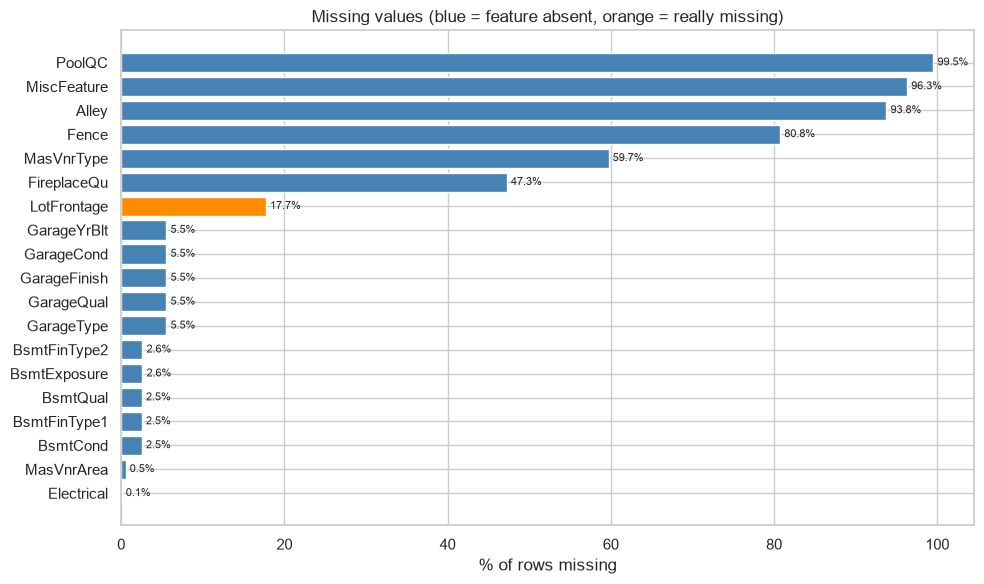

Duplicate rows (ignoring Id): 0


In [ ]:
# NA in these columns means "the house doesn't have it"
absent_cat = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu',
              'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType']
absent_num = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
              'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea']

missing = train_raw.isna().mean().mul(100)
missing = missing[missing > 0].sort_values()
colors = ['steelblue' if c in absent_cat + absent_num + ['GarageYrBlt'] else 'darkorange' for c in missing.index]

plt.figure(figsize=(10, 6))
plt.barh(missing.index, missing, color=colors)
for i, v in enumerate(missing):
    plt.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=8)
plt.xlabel('% of rows missing')
plt.title('Missing values (blue = feature absent, orange = really missing)')
save_show('eda_missing_values')

print('Duplicate rows (ignoring Id):', train_raw.drop(columns='Id').duplicated().sum())

## A4. Target variable

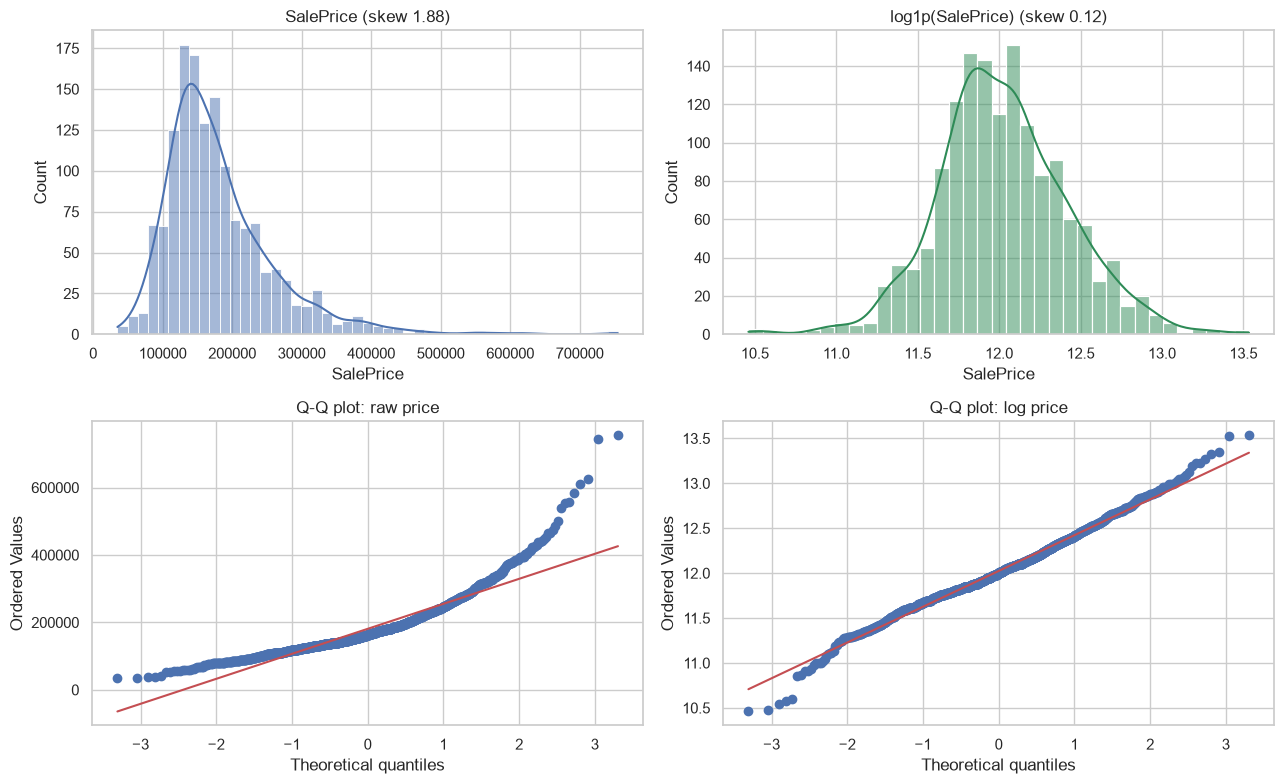

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

In [ ]:
price = train_raw['SalePrice']
log_price = np.log1p(price)

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.histplot(price, kde=True, ax=ax[0, 0]).set_title(f'SalePrice (skew {price.skew():.2f})')
sns.histplot(log_price, kde=True, ax=ax[0, 1], color='seagreen').set_title(f'log1p(SalePrice) (skew {log_price.skew():.2f})')
stats.probplot(price, plot=ax[1, 0]); ax[1, 0].set_title('Q-Q plot: raw price')
stats.probplot(log_price, plot=ax[1, 1]); ax[1, 1].set_title('Q-Q plot: log price')
save_show('eda_target_distribution')
price.describe().round(0)

## A5. Univariate analysis

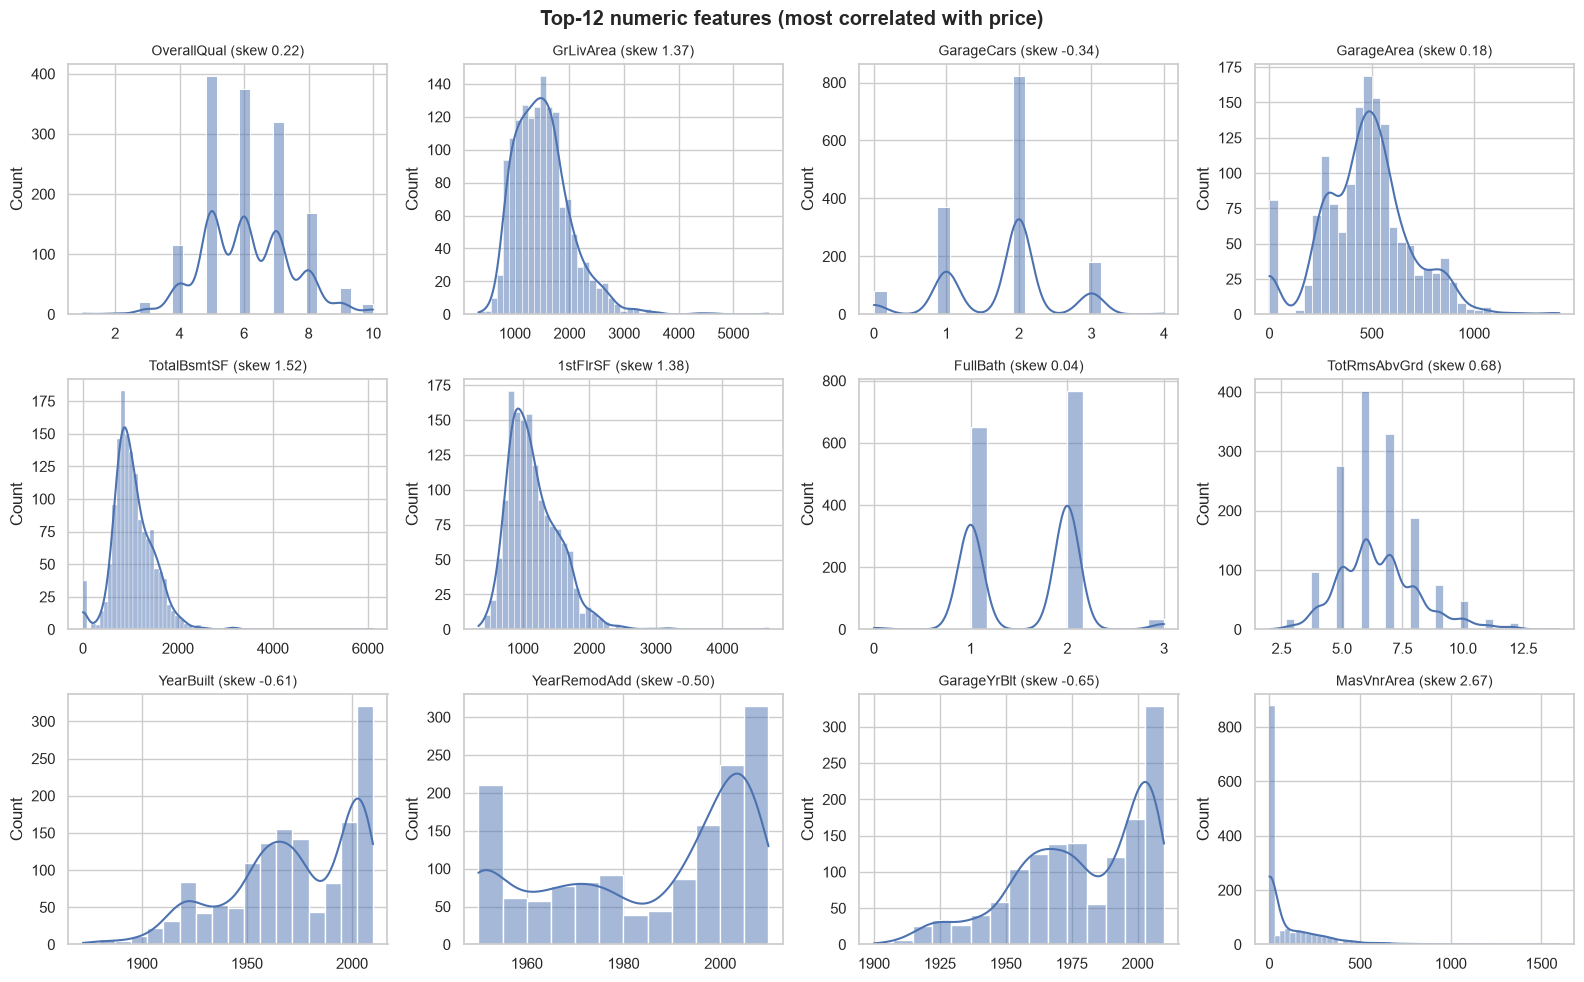

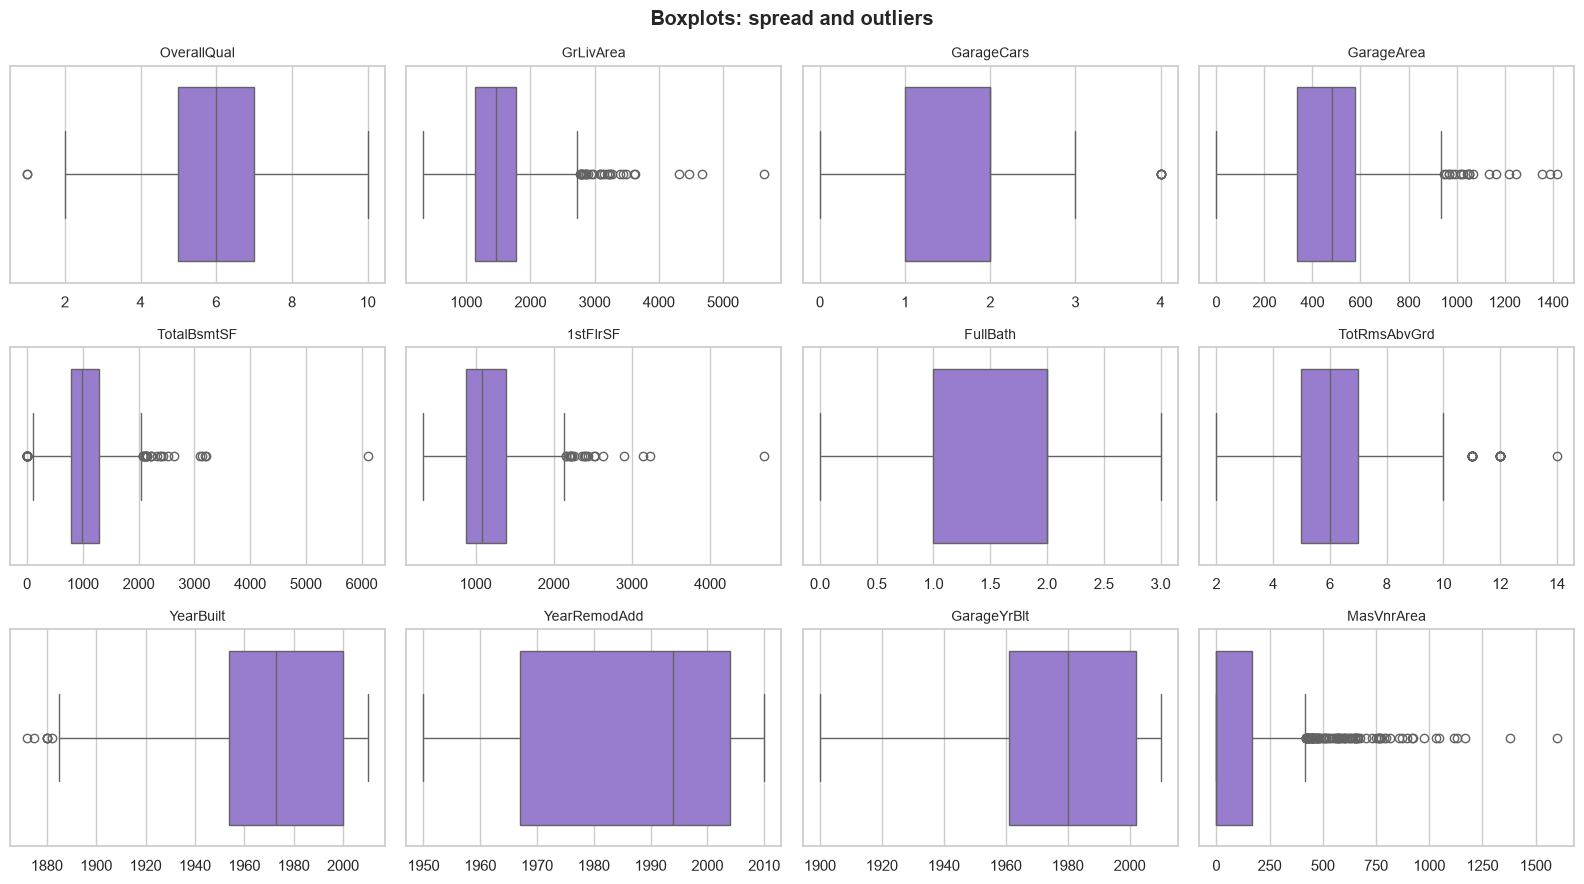

In [ ]:
corr_price = train_raw[num_cols + ['SalePrice']].corr()['SalePrice'].drop('SalePrice')
top12 = corr_price.abs().sort_values(ascending=False).index[:12]

fig, ax = plt.subplots(3, 4, figsize=(16, 10))
for a, col in zip(ax.flat, top12):
    sns.histplot(train_raw[col], kde=True, ax=a)
    a.set_title(f'{col} (skew {train_raw[col].skew():.2f})', fontsize=10)
    a.set_xlabel('')
fig.suptitle('Top-12 numeric features (most correlated with price)', fontweight='bold')
save_show('eda_numeric_histograms')

fig, ax = plt.subplots(3, 4, figsize=(16, 9))
for a, col in zip(ax.flat, top12):
    sns.boxplot(x=train_raw[col], ax=a, color='mediumpurple')
    a.set_title(col, fontsize=10)
    a.set_xlabel('')
fig.suptitle('Boxplots: spread and outliers', fontweight='bold')
save_show('eda_numeric_boxplots')

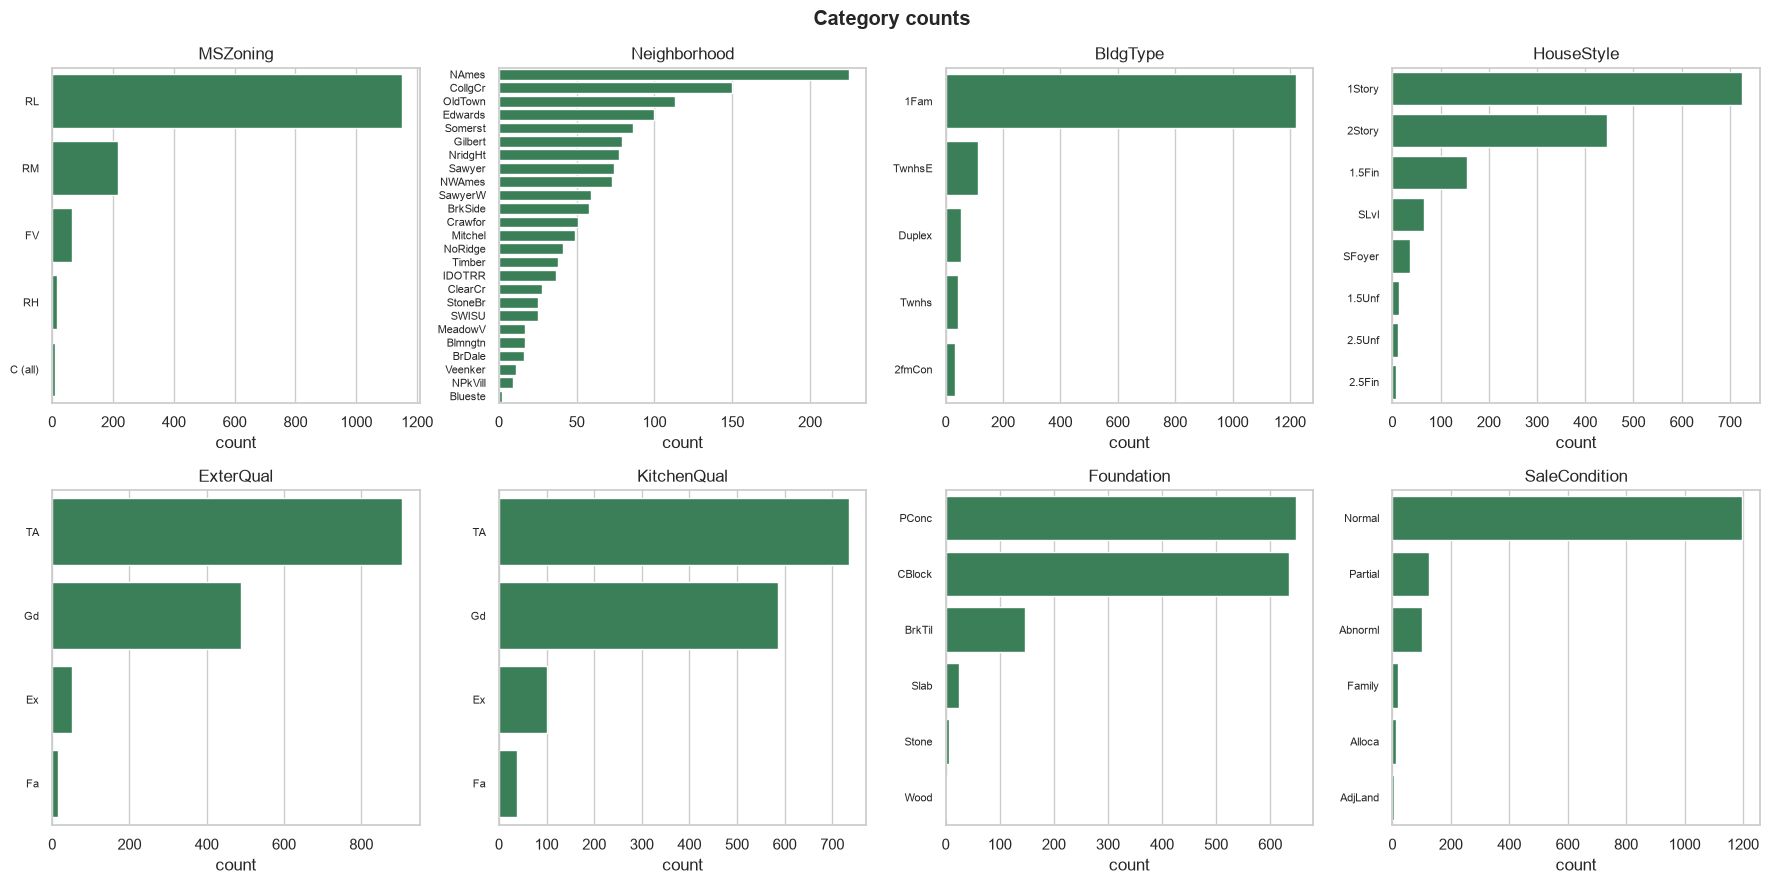

In [ ]:
show_cats = ['MSZoning', 'Neighborhood', 'BldgType', 'HouseStyle', 'ExterQual', 'KitchenQual', 'Foundation', 'SaleCondition']
fig, ax = plt.subplots(2, 4, figsize=(18, 9))
for a, col in zip(ax.flat, show_cats):
    sns.countplot(y=train_raw[col], order=train_raw[col].value_counts().index, ax=a, color='seagreen')
    a.set_title(col)
    a.set_ylabel('')
    a.tick_params(axis='y', labelsize=8)
fig.suptitle('Category counts', fontweight='bold')
save_show('eda_categorical_bars')

## A6. Bivariate analysis (feature vs price)

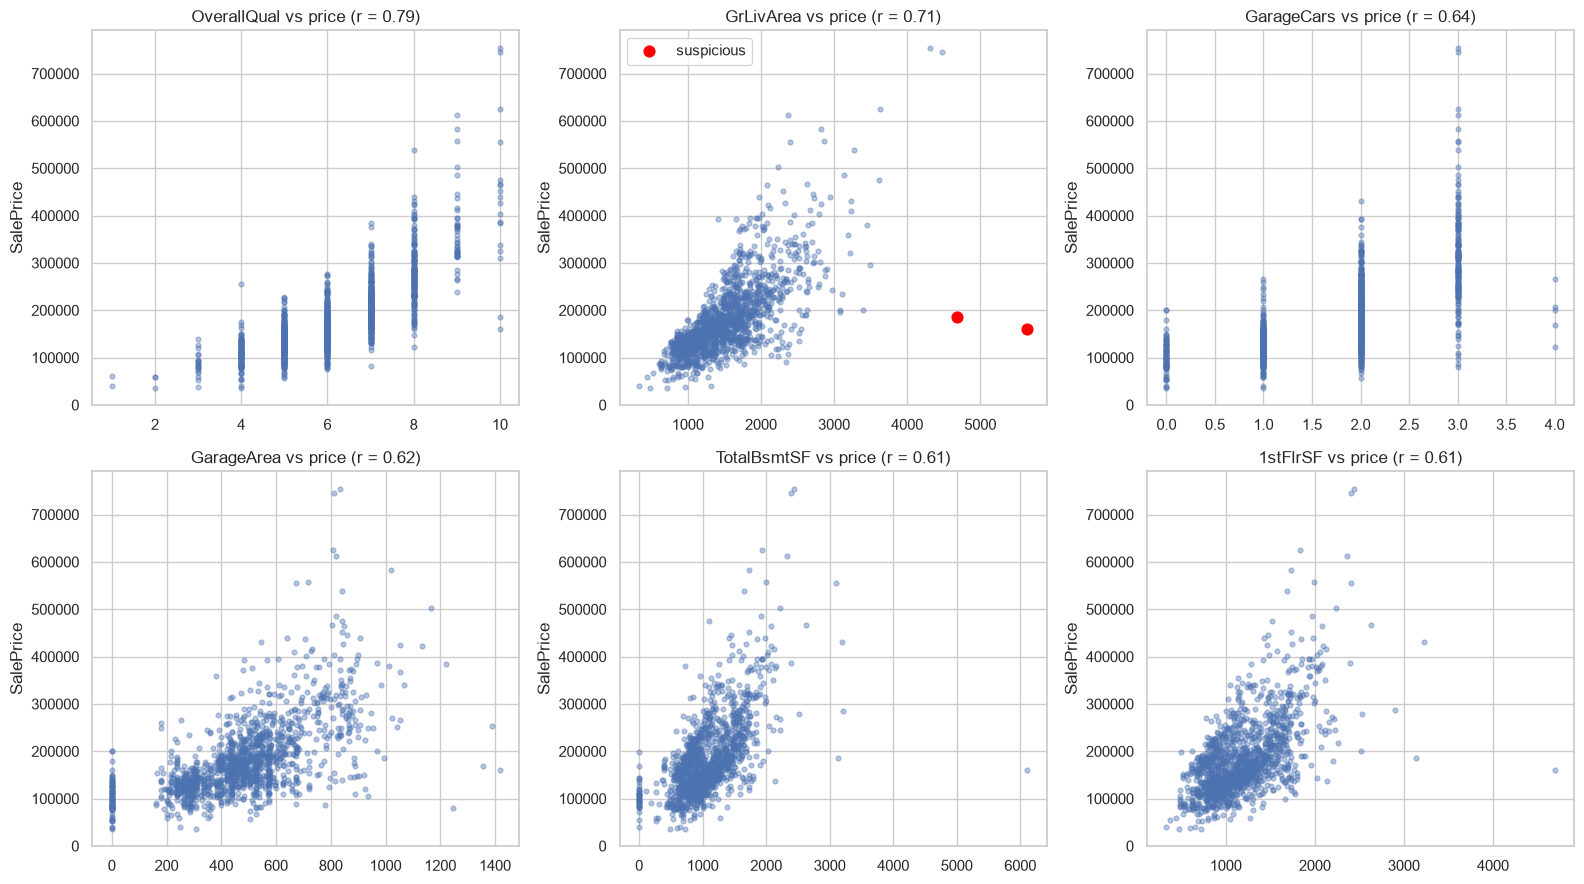

In [ ]:
odd = (train_raw['GrLivArea'] > 4000) & (train_raw['SalePrice'] < 300000)

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, col in zip(ax.flat, top12[:6]):
    a.scatter(train_raw[col], train_raw['SalePrice'], s=12, alpha=0.4)
    if col == 'GrLivArea':
        a.scatter(train_raw.loc[odd, col], train_raw.loc[odd, 'SalePrice'], color='red', s=60, label='suspicious')
        a.legend()
    a.set_title(f'{col} vs price (r = {corr_price[col]:.2f})')
    a.set_ylabel('SalePrice')
save_show('eda_bivariate_scatter')

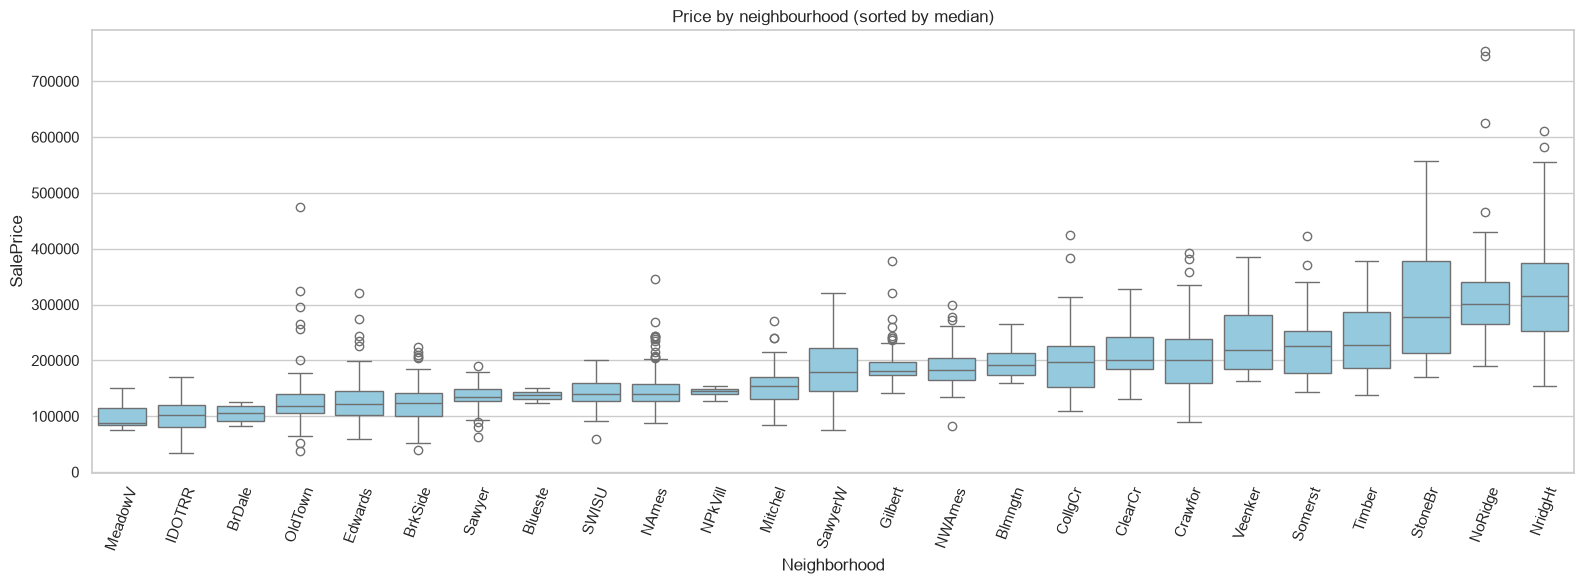

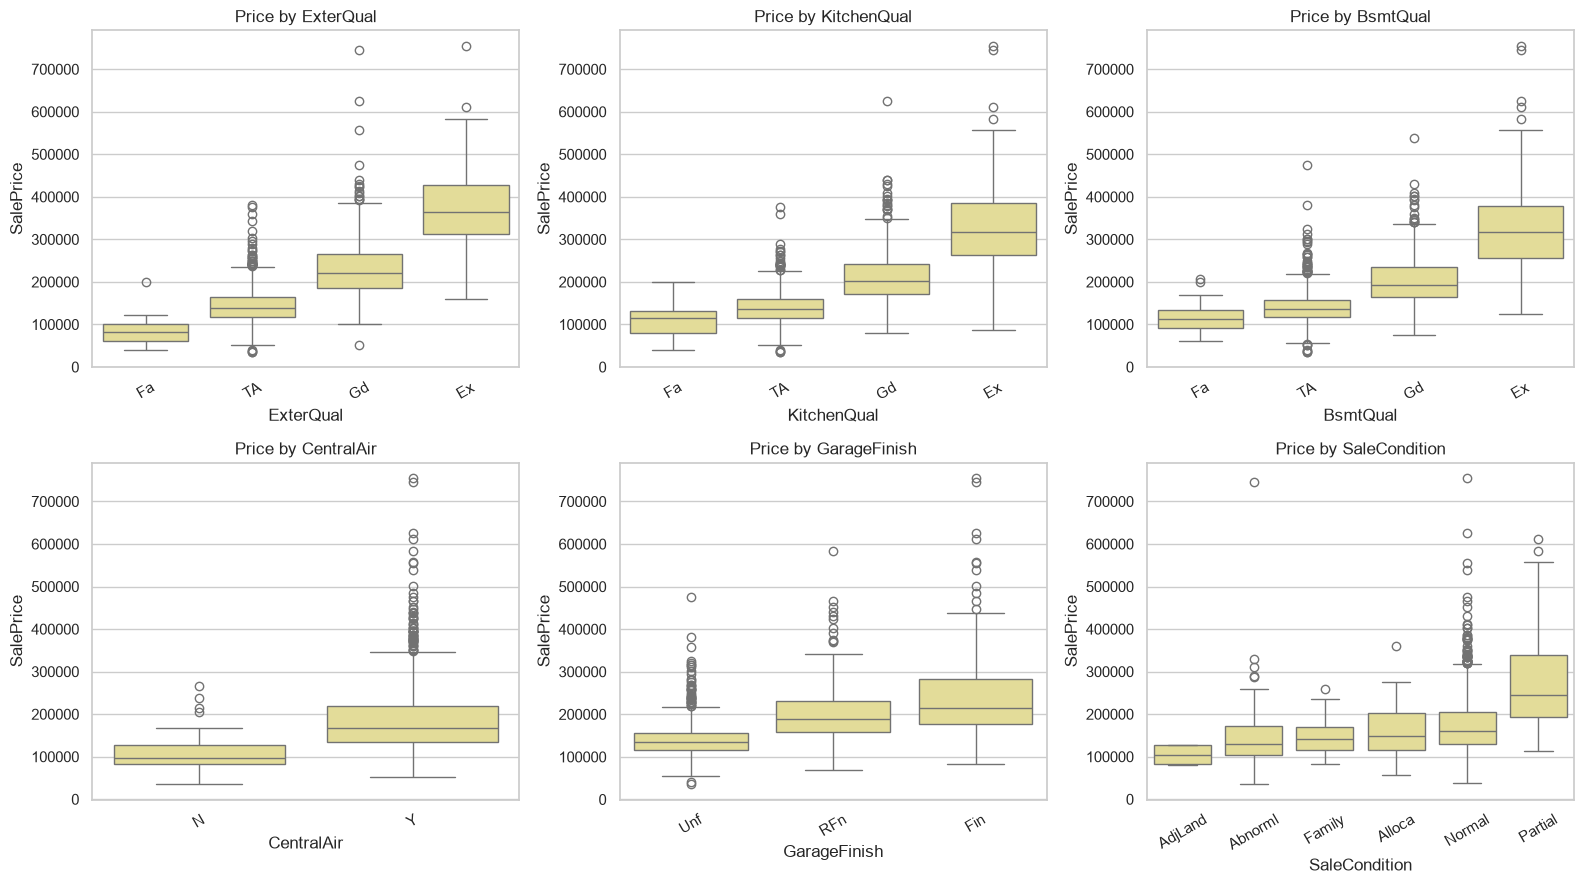

In [ ]:
order = train_raw.groupby('Neighborhood')['SalePrice'].median().sort_values().index
plt.figure(figsize=(16, 6))
sns.boxplot(data=train_raw, x='Neighborhood', y='SalePrice', order=order, color='skyblue')
plt.xticks(rotation=70)
plt.title('Price by neighbourhood (sorted by median)')
save_show('eda_neighborhood_vs_price')

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, col in zip(ax.flat, ['ExterQual', 'KitchenQual', 'BsmtQual', 'CentralAir', 'GarageFinish', 'SaleCondition']):
    order = train_raw.groupby(col)['SalePrice'].median().sort_values().index
    sns.boxplot(data=train_raw, x=col, y='SalePrice', order=order, ax=a, color='khaki')
    a.set_title(f'Price by {col}')
    a.tick_params(axis='x', rotation=30)
save_show('eda_categorical_vs_price')

## A7. Multivariate analysis (correlations)

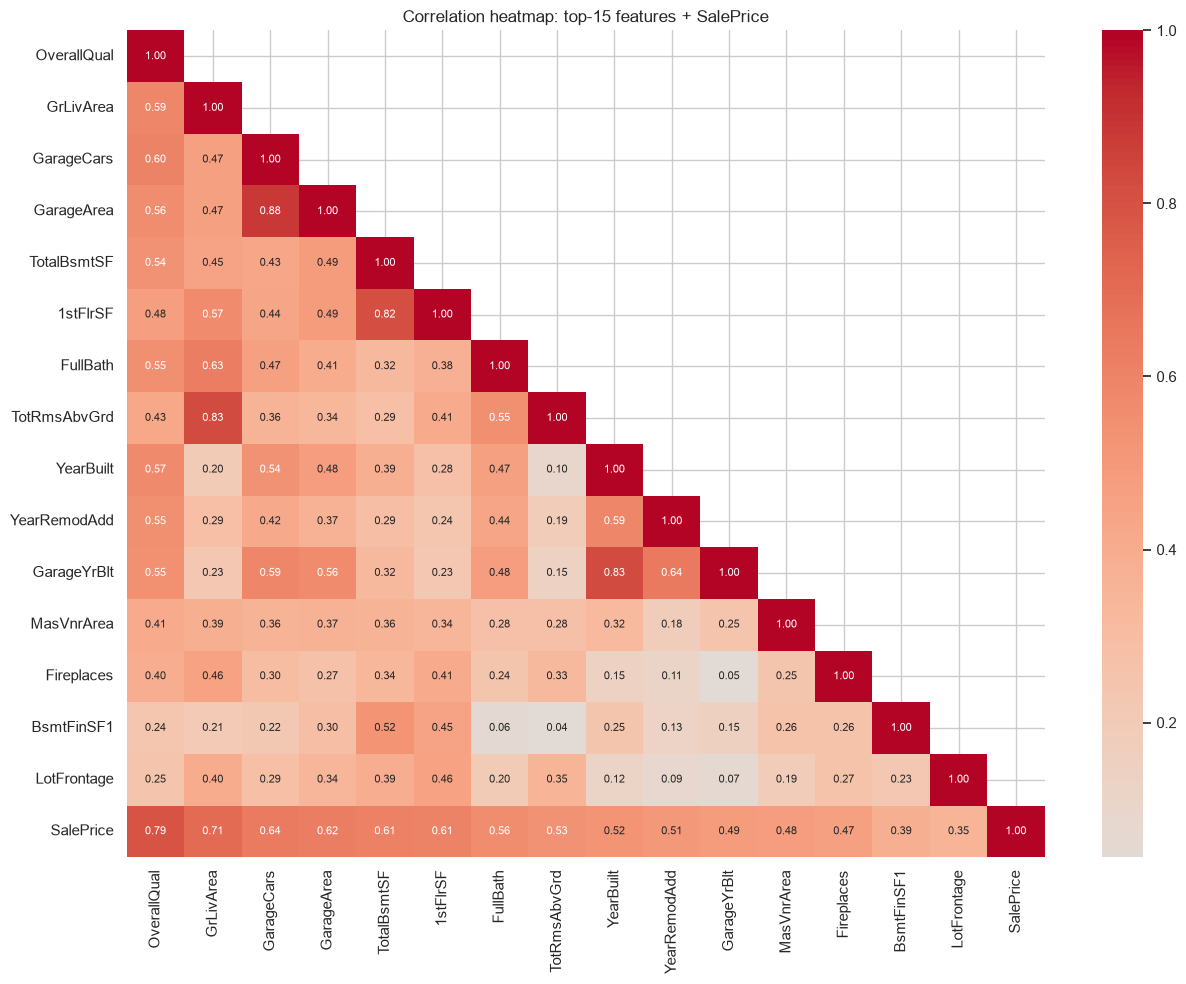

In [ ]:
top15 = corr_price.abs().sort_values(ascending=False).index[:15].tolist()
corr = train_raw[top15 + ['SalePrice']].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Correlation heatmap: top-15 features + SalePrice')
save_show('eda_correlation_heatmap')

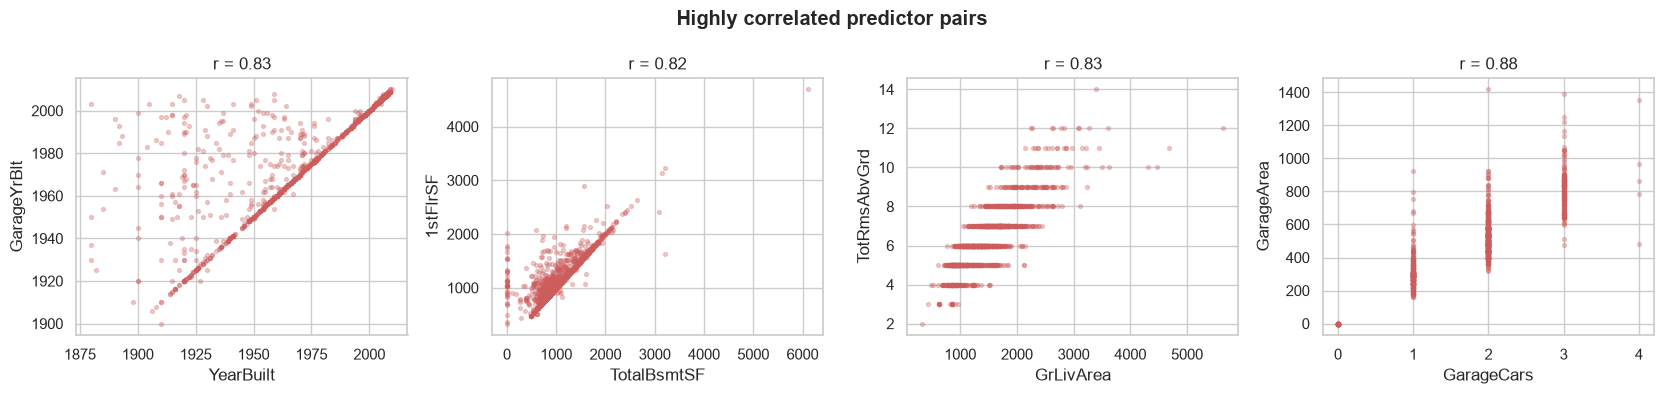

,feature_1,feature_2,r
0,YearBuilt,GarageYrBlt,0.83
1,TotalBsmtSF,1stFlrSF,0.82
2,GrLivArea,TotRmsAbvGrd,0.83
3,GarageCars,GarageArea,0.88


In [ ]:
# predictor pairs that carry almost the same information (|r| > 0.8)
c = train_raw[num_cols].corr().abs()
pairs = [(a, b, round(c.loc[a, b], 2)) for i, a in enumerate(num_cols) for b in num_cols[i + 1:] if c.loc[a, b] > 0.8]
pairs = pd.DataFrame(pairs, columns=['feature_1', 'feature_2', 'r'])

fig, ax = plt.subplots(1, len(pairs), figsize=(4.2 * len(pairs), 4))
for a, (_, p) in zip(ax, pairs.iterrows()):
    a.scatter(train_raw[p.feature_1], train_raw[p.feature_2], s=8, alpha=0.3, color='indianred')
    a.set_xlabel(p.feature_1)
    a.set_ylabel(p.feature_2)
    a.set_title(f'r = {p.r}')
fig.suptitle('Highly correlated predictor pairs', fontweight='bold')
save_show('eda_multicollinearity_pairs')
pairs

## A8. Data cleaning (row-by-row fixes only, so no leakage)
Every fix here looks at **one row at a time** and learns nothing from other rows, so it is safe to do before the split. Filling gaps with a median or mode *learns* from the data, so Part B does that after the split, using the training rows only.

In [ ]:
def basic_clean(df):
    df = df.copy()
    df[absent_cat] = df[absent_cat].fillna('None')           # no pool -> 'None'
    df[absent_num] = df[absent_num].fillna(0)                 # no basement -> 0 sq ft
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])   # no garage -> use house year
    df['MSSubClass'] = df['MSSubClass'].astype(str)           # building class code, not a number
    return df

train_clean = basic_clean(train_raw).drop_duplicates(subset=train_raw.columns.drop('Id'))
test_clean = basic_clean(test_raw)

left = train_clean.isna().sum()
print('Rows after removing duplicates:', len(train_clean))
print('Still missing (handled in Part B, after the split):')
print(left[left > 0])

Rows after removing duplicates: 1460
Still missing (handled in Part B, after the split):
LotFrontage    259
Electrical       1
dtype: int64


## A9. EDA insight log

In [ ]:
nb_median = train_raw.groupby('Neighborhood')['SalePrice'].median()
share_top = train_raw[all_features].apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])

insights = pd.DataFrame([
    ['Price is right-skewed', f'skew {price.skew():.2f} -> {log_price.skew():.2f} after log', 'Model log1p(price), report errors in USD'],
    ['Quality and size drive price', ', '.join(f'{c} {corr_price[c]:.2f}' for c in top12[:4]), 'Build TotalSF / TotalBath; ordinal-encode quality'],
    ['Most gaps mean "feature absent"', f'{len(missing)} columns with gaps', "Fill 'None'/0; impute real gaps from train only"],
    ['Two extreme outliers', f'{odd.sum()} houses > 4000 sq ft sold < 300k', 'Remove from the training split only'],
    ['Location matters a lot', f'median {nb_median.min():,.0f} to {nb_median.max():,.0f} USD', 'Keep Neighborhood (one-hot)'],
    ['Quality ratings are ordered', 'price rises Fa < TA < Gd < Ex', 'Ordinal encoding, not one-hot'],
    ['Some predictors duplicate each other', f'{len(pairs)} pairs with |r| > 0.8', 'Drop the weaker one of each pair'],
    ['Some columns barely vary', f'{(share_top >= 0.95).sum()} columns are >= 95% one value', 'Drop near-constant columns'],
    ['Target is continuous', 'hundreds of distinct prices', 'Regression metrics; ROC/AUC does not apply'],
], columns=['Insight', 'Evidence', 'Decision'])
insights

,Insight,Evidence,Decision
0,Price is right-skewed,skew 1.88 -> 0.12 after log,"Model log1p(price), report errors in USD"
1,Quality and size drive price,"OverallQual 0.79, GrLivArea 0.71, GarageCars 0...",Build TotalSF / TotalBath; ordinal-encode quality
2,"Most gaps mean ""feature absent""",19 columns with gaps,Fill 'None'/0; impute real gaps from train only
3,Two extreme outliers,2 houses > 4000 sq ft sold < 300k,Remove from the training split only
4,Location matters a lot,"median 88,000 to 315,000 USD",Keep Neighborhood (one-hot)
5,Quality ratings are ordered,price rises Fa < TA < Gd < Ex,"Ordinal encoding, not one-hot"
6,Some predictors duplicate each other,4 pairs with |r| > 0.8,Drop the weaker one of each pair
7,Some columns barely vary,12 columns are >= 95% one value,Drop near-constant columns
8,Target is continuous,hundreds of distinct prices,Regression metrics; ROC/AUC does not apply


---
# Part B — Preprocessing & feature engineering
**Owner: IT24100871 — Senevirathne J.A.D.T.**

## B1. Stratified train / validation / test split (70 / 15 / 15)
The split comes **first**, before anything is learned from the data.

`stratify` needs groups, but price is a continuous number. So we cut price into 10 bands (deciles) with `pd.qcut` and stratify on the bands. That way each split gets the same mix of cheap and expensive homes. The bands are only used to split. The models still learn the real price.

train 1022 | validation 219 | test 219


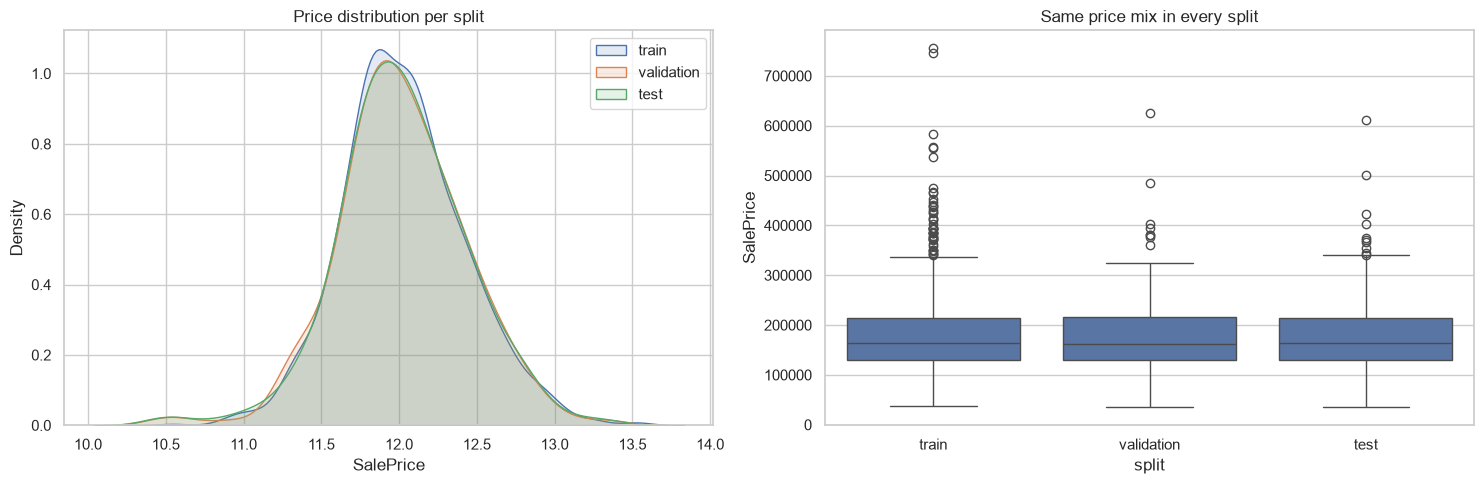

In [ ]:
price_band = pd.qcut(train_clean['SalePrice'], q=10, labels=False)

train_df, temp_df = train_test_split(train_clean, test_size=0.30, stratify=price_band, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=price_band[temp_df.index], random_state=SEED)
print(f'train {len(train_df)} | validation {len(val_df)} | test {len(test_df)}')

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for name, d in [('train', train_df), ('validation', val_df), ('test', test_df)]:
    sns.kdeplot(np.log1p(d['SalePrice']), ax=ax[0], label=name, fill=True, alpha=0.15)
ax[0].set_title('Price distribution per split')
ax[0].legend()
split_view = pd.concat([train_df.assign(split='train'), val_df.assign(split='validation'), test_df.assign(split='test')])
sns.boxplot(data=split_view, x='split', y='SalePrice', ax=ax[1])
ax[1].set_title('Same price mix in every split')
save_show('split_stratification_check')

## B2. Missing-value strategy (learned from the training split only)

In [ ]:
lot_by_area = train_df.groupby('Neighborhood')['LotFrontage'].median()
lot_median = train_df['LotFrontage'].median()
electrical_mode = train_df['Electrical'].mode()[0]

def fill_missing(df):
    df = df.copy()
    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(lot_by_area)).fillna(lot_median)
    df['Electrical'] = df['Electrical'].fillna(electrical_mode)
    return df

train_df, val_df, test_df, sub_df = [fill_missing(d) for d in (train_df, val_df, test_df, test_clean)]
print('LotFrontage = neighbourhood median (train), Electrical =', electrical_mode)
print('Missing left - train:', train_df.isna().sum().sum(), '| val:', val_df.isna().sum().sum(),
      '| test:', test_df.isna().sum().sum(), '| Kaggle test:', sub_df.isna().sum().sum(), '(pipeline imputers fill these)')

LotFrontage = neighbourhood median (train), Electrical = SBrkr
Missing left - train: 0 | val: 0 | test: 0 | Kaggle test: 12 (pipeline imputers fill these)


## B3. Outliers (training split only)

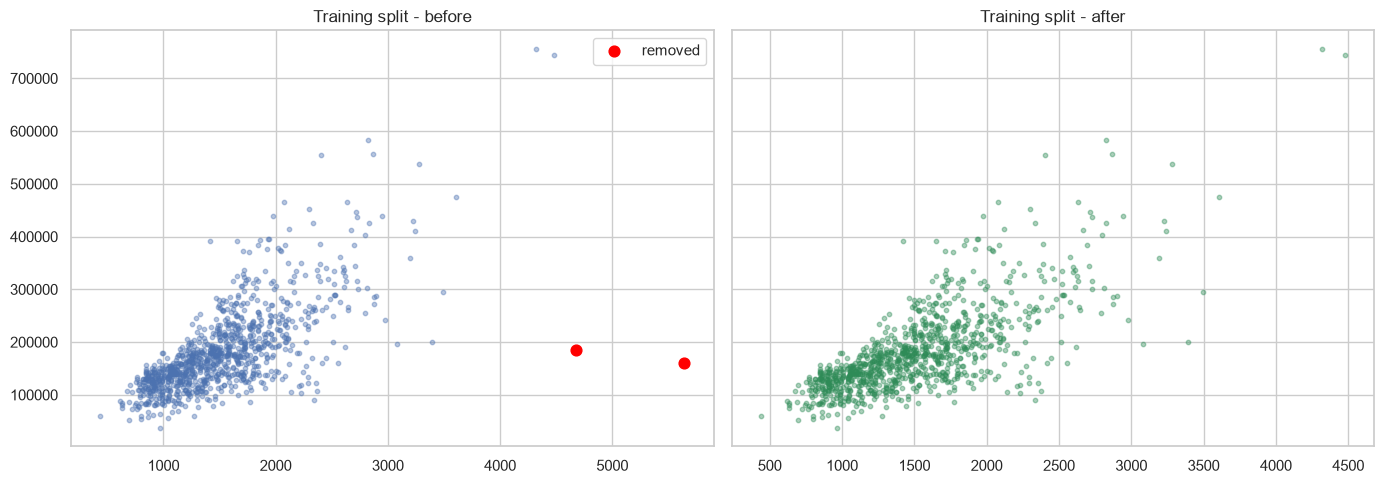

Removed 2 outliers from training only (validation/test keep real-world data)


In [ ]:
is_outlier = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
ax[0].scatter(train_df['GrLivArea'], train_df['SalePrice'], s=10, alpha=0.4)
ax[0].scatter(train_df.loc[is_outlier, 'GrLivArea'], train_df.loc[is_outlier, 'SalePrice'], color='red', s=60, label='removed')
ax[0].set_title('Training split - before')
ax[0].legend()
train_df = train_df[~is_outlier]
ax[1].scatter(train_df['GrLivArea'], train_df['SalePrice'], s=10, alpha=0.4, color='seagreen')
ax[1].set_title('Training split - after')
save_show('outlier_removal_train_only')
print(f'Removed {is_outlier.sum()} outliers from training only (validation/test keep real-world data)')

for d in (train_df, val_df, test_df):
    d['SalePrice_log'] = np.log1p(d['SalePrice'])
y_train, y_val, y_test = train_df['SalePrice_log'], val_df['SalePrice_log'], test_df['SalePrice_log']

## B4. Feature engineering

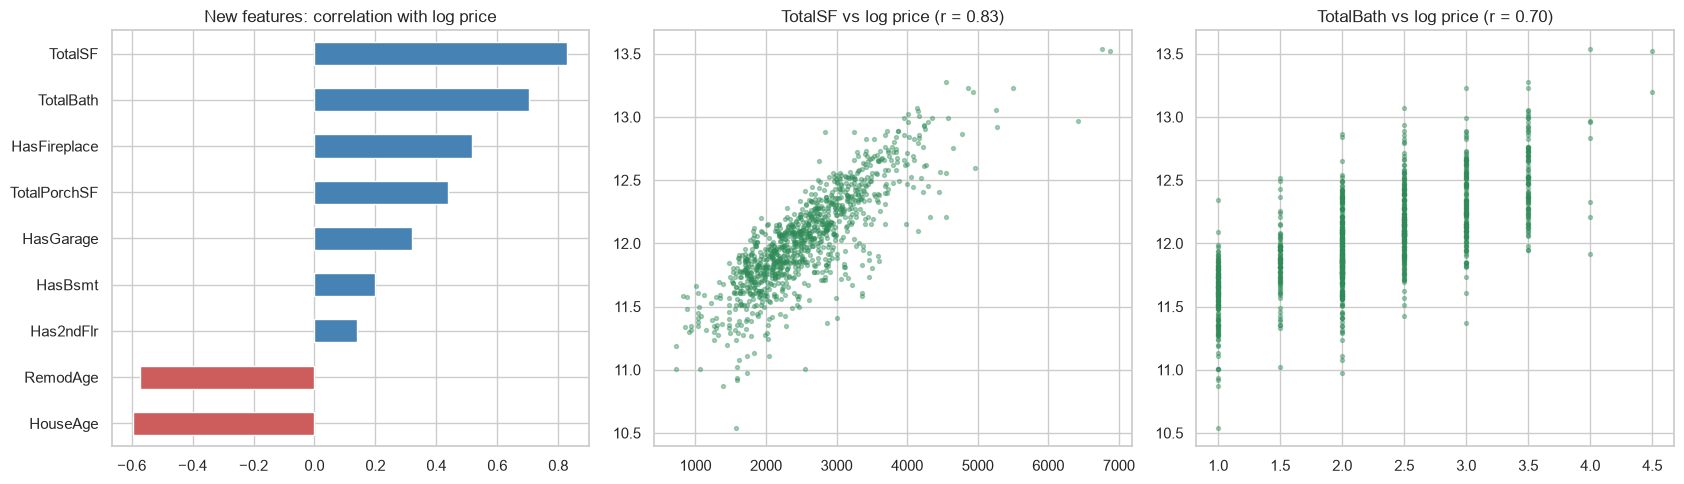

In [ ]:
def add_features(df):
    df = df.copy()
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = df['FullBath'] + 0.5 * df['HalfBath'] + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath']
    df['HouseAge'] = (df['YrSold'] - df['YearBuilt']).clip(lower=0)
    df['RemodAge'] = (df['YrSold'] - df['YearRemodAdd']).clip(lower=0)
    df['TotalPorchSF'] = df[['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'WoodDeckSF']].sum(axis=1)
    df['HasGarage'] = (df['GarageArea'] > 0).astype(int)
    df['HasBsmt'] = (df['TotalBsmtSF'] > 0).astype(int)
    df['Has2ndFlr'] = (df['2ndFlrSF'] > 0).astype(int)
    df['HasFireplace'] = (df['Fireplaces'] > 0).astype(int)
    return df

new_features = ['TotalSF', 'TotalBath', 'HouseAge', 'RemodAge', 'TotalPorchSF', 'HasGarage', 'HasBsmt', 'Has2ndFlr', 'HasFireplace']
train_df, val_df, test_df, sub_df = [add_features(d) for d in (train_df, val_df, test_df, sub_df)]

new_r = train_df[new_features].corrwith(y_train).sort_values()
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
new_r.plot(kind='barh', ax=ax[0], color=['indianred' if v < 0 else 'steelblue' for v in new_r])
ax[0].set_title('New features: correlation with log price')
for a, col in zip(ax[1:], ['TotalSF', 'TotalBath']):
    a.scatter(train_df[col], y_train, s=8, alpha=0.4, color='seagreen')
    a.set_title(f'{col} vs log price (r = {new_r[col]:.2f})')
save_show('feature_engineering_signal')

## B5. Feature reduction: find the candidates (training split only)
1. **Near-constant**: one value in ≥ 95% of rows, so there's almost no information.
2. **Multicollinearity**: pairs with |r| > 0.8. Keep the one more related to price and drop the other.
3. **Weak correlation**: |r| < 0.10 with price.

These are only *candidates*. In B7 each one is checked on the validation set before we actually drop it.

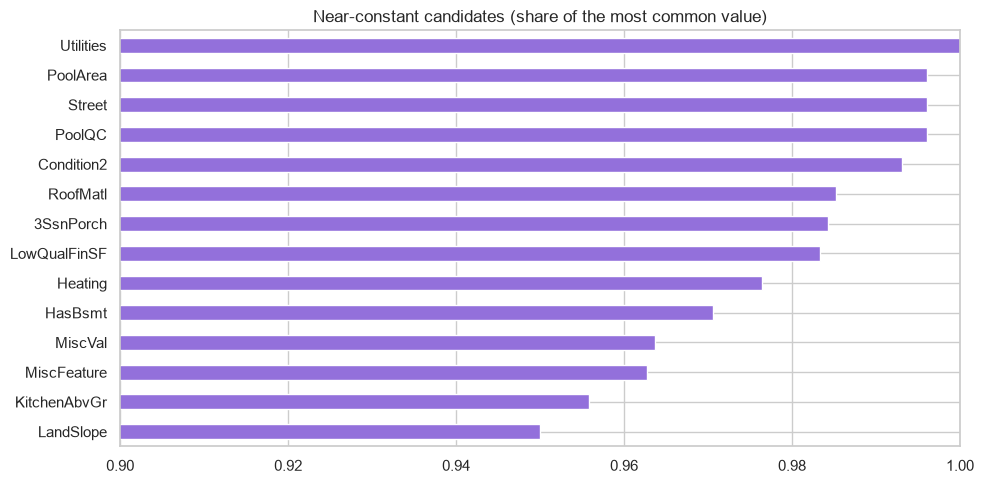

Near-constant: ['LandSlope', 'KitchenAbvGr', 'MiscFeature', 'MiscVal', 'HasBsmt', 'Heating', 'LowQualFinSF', '3SsnPorch', 'RoofMatl', 'Condition2', 'PoolQC', 'Street', 'PoolArea', 'Utilities']


In [ ]:
all_cols = train_df.columns.drop(['Id', 'SalePrice', 'SalePrice_log']).tolist()

# 1) near-constant
top_share = train_df[all_cols].apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
near_constant = top_share[top_share >= 0.95].sort_values()
near_constant.plot(kind='barh', figsize=(10, 5), color='mediumpurple', xlim=(0.9, 1.0),
                   title='Near-constant candidates (share of the most common value)')
save_show('reduction_near_constant')
print('Near-constant:', list(near_constant.index))

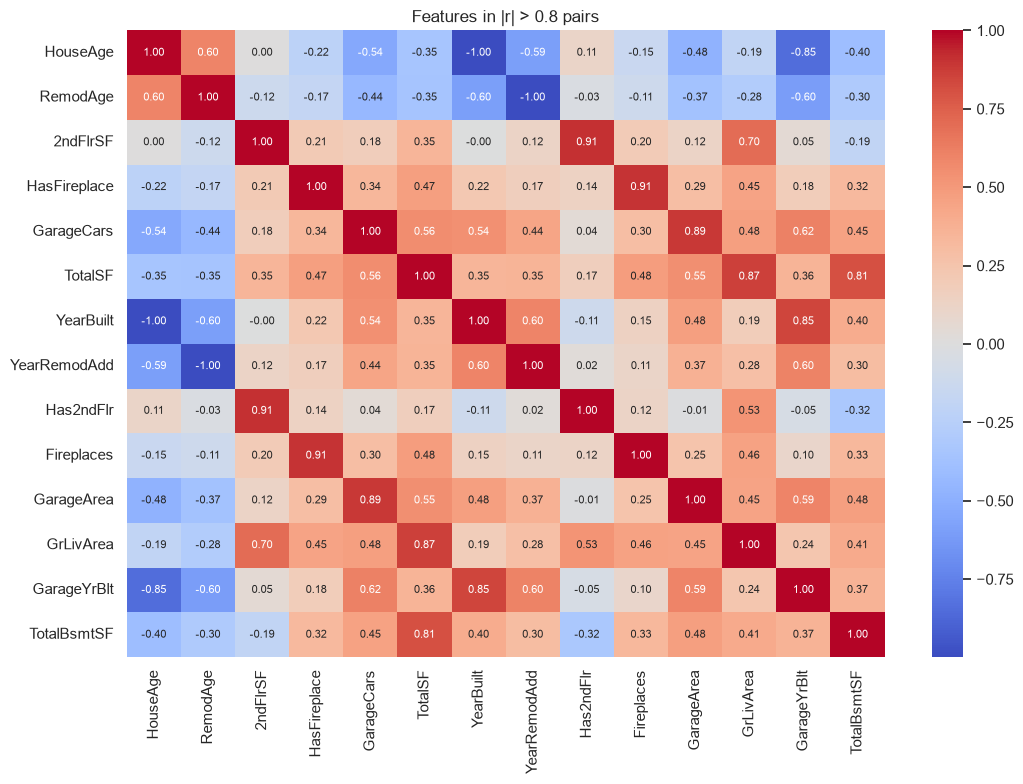

,keep,drop,r between,r keep~price,r drop~price
0,HouseAge,YearBuilt,0.999,0.595,0.594
1,RemodAge,YearRemodAdd,0.998,0.572,0.571
2,2ndFlrSF,Has2ndFlr,0.912,0.316,0.141
3,HasFireplace,Fireplaces,0.905,0.517,0.498
4,GarageCars,GarageArea,0.887,0.684,0.650
5,TotalSF,GrLivArea,0.865,0.830,0.719
6,HouseAge,GarageYrBlt,0.847,0.595,0.577
7,TotalSF,TotalBsmtSF,0.807,0.830,0.664


In [ ]:
# 2) multicollinearity - check the strongest pairs first
num = train_df[[c for c in all_cols if c not in near_constant.index]].select_dtypes('number').columns.tolist()
c = train_df[num].corr().abs()
r_price = train_df[num].corrwith(y_train).abs()
high = sorted([(c.loc[a, b], a, b) for i, a in enumerate(num) for b in num[i + 1:] if c.loc[a, b] > 0.8], reverse=True)

mc_drop, mc_rows = [], []
for r, a, b in high:
    if a in mc_drop or b in mc_drop:
        continue
    keep, drop = (a, b) if r_price[a] >= r_price[b] else (b, a)
    mc_drop.append(drop)
    mc_rows.append([keep, drop, round(r, 3), round(r_price[keep], 3), round(r_price[drop], 3)])

mc_table = pd.DataFrame(mc_rows, columns=['keep', 'drop', 'r between', 'r keep~price', 'r drop~price'])
plt.figure(figsize=(11, 8))
involved = mc_table['keep'].tolist() + mc_table['drop'].tolist()
sns.heatmap(train_df[list(dict.fromkeys(involved))].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Features in |r| > 0.8 pairs')
save_show('reduction_multicollinearity_heatmap')
mc_table

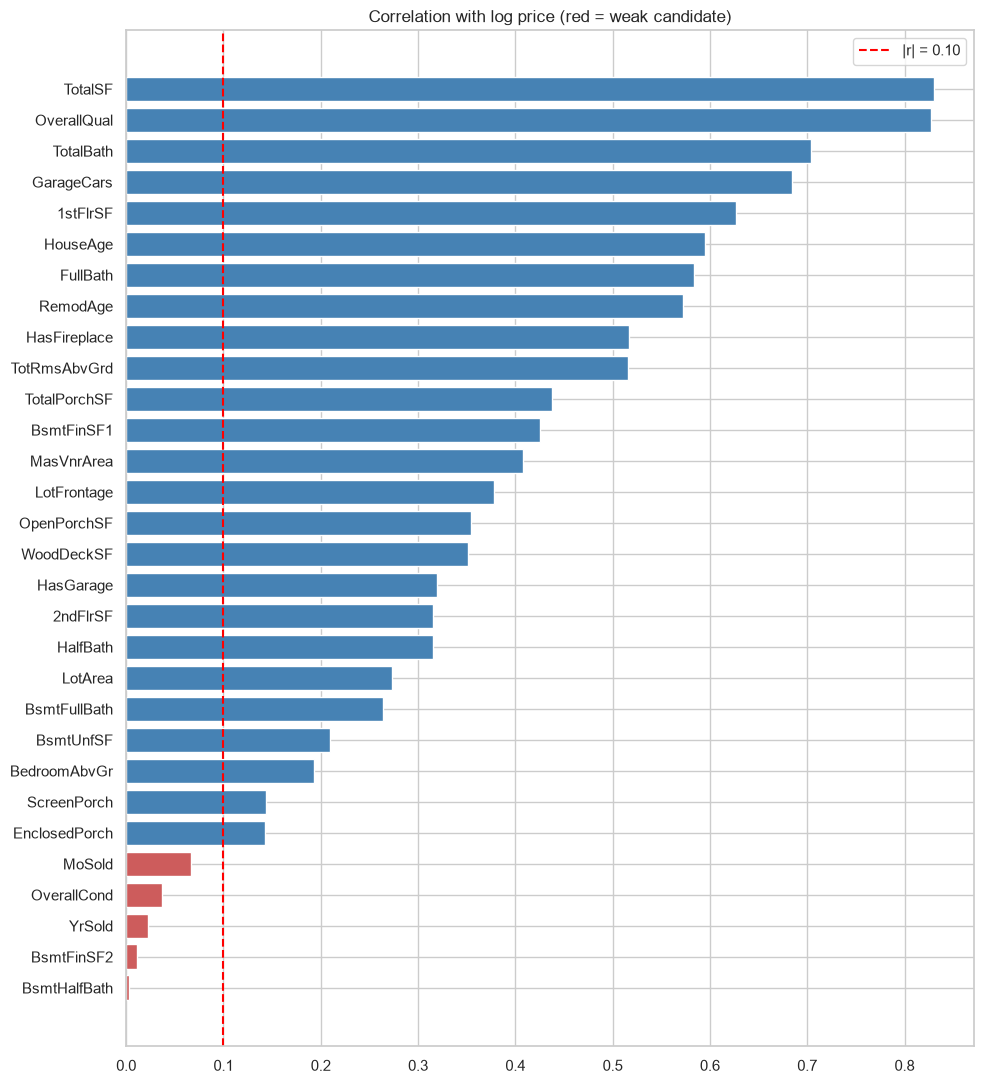

Weak candidates: ['OverallCond', 'BsmtFinSF2', 'BsmtHalfBath', 'MoSold', 'YrSold']


In [ ]:
# 3) weak correlation with price
r_all = train_df[[x for x in num if x not in mc_drop]].corrwith(y_train)
weak = r_all[r_all.abs() < 0.10].index.tolist()

r_sorted = r_all.abs().sort_values()
plt.figure(figsize=(10, 11))
plt.barh(r_sorted.index, r_sorted, color=['indianred' if x in weak else 'steelblue' for x in r_sorted.index])
plt.axvline(0.10, color='red', ls='--', label='|r| = 0.10')
plt.title('Correlation with log price (red = weak candidate)')
plt.legend()
save_show('reduction_weak_correlation')
print('Weak candidates:', weak)

## B6. Encoding & scaling pipeline
Everything is fitted on the **training split only**. Inside cross-validation it is re-fitted on each training fold, so no information leaks between folds.

| Column group | Steps |
|---|---|
| Skewed numeric | fill median → log1p → scale |
| Other numeric | fill median → scale |
| Quality ratings (ordered) | fill most common → ordinal encoding (Po < Fa < TA < Gd < Ex) → scale |
| Other categories | fill most common → one-hot encoding (unknown categories ignored) |

In [ ]:
Q = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
ORDER = {'ExterQual': Q, 'ExterCond': Q, 'HeatingQC': Q, 'KitchenQual': Q,
         'BsmtQual': ['None'] + Q, 'BsmtCond': ['None'] + Q, 'FireplaceQu': ['None'] + Q,
         'GarageQual': ['None'] + Q, 'GarageCond': ['None'] + Q, 'PoolQC': ['None'] + Q,
         'BsmtExposure': ['None', 'No', 'Mn', 'Av', 'Gd'],
         'BsmtFinType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
         'BsmtFinType2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
         'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'], 'PavedDrive': ['N', 'P', 'Y'],
         'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
         'LotShape': ['IR3', 'IR2', 'IR1', 'Reg'], 'CentralAir': ['N', 'Y']}

def build_preprocessor(cols):
    numeric = train_df[cols].select_dtypes('number').columns
    skewed = [c for c in numeric if abs(train_df[c].skew()) > 0.75 and train_df[c].min() >= 0]
    normal = [c for c in numeric if c not in skewed]
    ordinal = [c for c in cols if c in ORDER]
    nominal = [c for c in cols if c not in numeric and c not in ORDER]
    return ColumnTransformer([
        ('skewed', Pipeline([('fill', SimpleImputer(strategy='median')),
                             ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                             ('scale', StandardScaler())]), skewed),
        ('normal', Pipeline([('fill', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), normal),
        ('ordinal', Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                              ('encode', OrdinalEncoder(categories=[ORDER[c] for c in ordinal],
                                                        handle_unknown='use_encoded_value', unknown_value=-1)),
                              ('scale', StandardScaler())]), ordinal),
        ('nominal', Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                              ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), nominal),
    ])

def prep_steps(cols, var_filter=False, pca=False):
    steps = [('prep', build_preprocessor(cols))]
    if var_filter:
        steps.append(('var', VarianceThreshold(0.01)))   # drops dummy columns that are almost always 0
    if pca:
        steps.append(('pca', PCA(n_components=0.95, random_state=SEED)))
    return steps

def quick_val_rmse(cols, var_filter=False, pca=False):
    # average validation error of a quick linear model and a quick tree model
    errors = []
    for model in [Ridge(alpha=10), GradientBoostingRegressor(random_state=SEED)]:
        pipe = Pipeline(prep_steps(cols, var_filter, pca) + [('model', model)])
        pipe.fit(train_df[cols], y_train)
        errors.append(usd_rmse(y_val, pipe.predict(val_df[cols])))
    return np.mean(errors)

## B7. Confirm each reduction on the validation split
 A drop is accepted if the validation error gets at most 2% worse, because we prefer the simpler model. Weak features are tested one at a time, because correlation can miss non-straight-line effects.

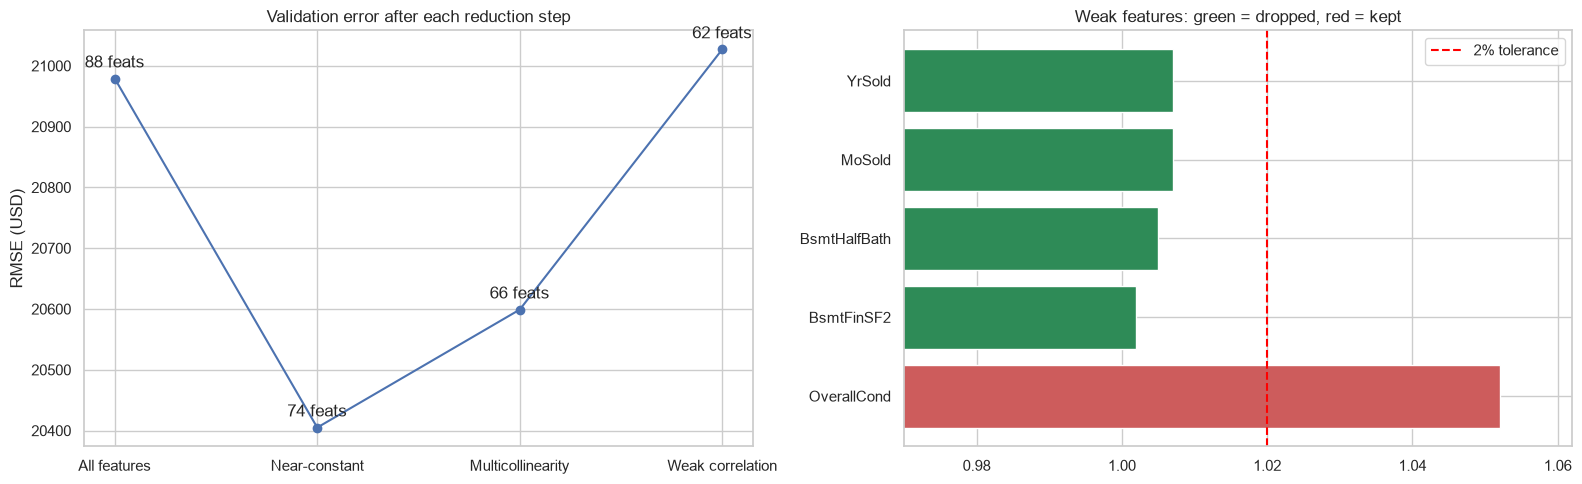

,step,features,val RMSE (USD),decision
0,All features,88,20979,start
1,Near-constant,74,20405,ACCEPT
2,Multicollinearity,66,20599,ACCEPT
3,Weak correlation,62,21027,one by one


,feature,r with price,error ratio if dropped,decision
0,OverallCond,-0.037,1.052,KEEP
1,BsmtFinSF2,0.011,1.002,DROP
2,BsmtHalfBath,0.003,1.005,DROP
3,MoSold,0.067,1.007,DROP
4,YrSold,-0.023,1.007,DROP


In [ ]:
TOL = 1.02
cols = all_cols.copy()
score = quick_val_rmse(cols)
steps_log = [['All features', len(cols), round(score), 'start']]

for step, drop in [('Near-constant', list(near_constant.index)), ('Multicollinearity', mc_drop)]:
    trial = [c for c in cols if c not in drop]
    s = quick_val_rmse(trial)
    ok = s <= score * TOL
    steps_log.append([step, len(trial), round(s), 'ACCEPT' if ok else 'REJECT'])
    if ok:
        cols, score = trial, s

weak_log = []
for w in weak:
    trial = [c for c in cols if c != w]
    s = quick_val_rmse(trial)
    ok = s <= score * TOL
    weak_log.append([w, round(r_all[w], 3), round(s / score, 3), 'DROP' if ok else 'KEEP'])
    if ok:
        cols, score = trial, s
steps_log.append(['Weak correlation', len(cols), round(score), 'one by one'])

FEATURES = cols
steps_log = pd.DataFrame(steps_log, columns=['step', 'features', 'val RMSE (USD)', 'decision'])
weak_log = pd.DataFrame(weak_log, columns=['feature', 'r with price', 'error ratio if dropped', 'decision'])

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(steps_log['step'], steps_log['val RMSE (USD)'], 'o-')
for i, row in steps_log.iterrows():
    ax[0].annotate(f"{row['features']} feats", (i, row['val RMSE (USD)']), textcoords='offset points', xytext=(0, 8), ha='center')
ax[0].set_title('Validation error after each reduction step')
ax[0].set_ylabel('RMSE (USD)')
ax[1].barh(weak_log['feature'], weak_log['error ratio if dropped'],
           color=['seagreen' if d == 'DROP' else 'indianred' for d in weak_log['decision']])
ax[1].axvline(TOL, color='red', ls='--', label='2% tolerance')
ax[1].set_xlim(0.97, max(1.06, weak_log['error ratio if dropped'].max() + 0.01))
ax[1].set_title('Weak features: green = dropped, red = kept')
ax[1].legend()
save_show('reduction_validation_check')
display(steps_log, weak_log)

## B8. Extra reduction methods: VarianceThreshold and PCA
- **VarianceThreshold (0.01)** runs *after* one-hot encoding and removes dummy columns that are almost always 0 (very rare categories). It's the same idea as near-constant, applied to the encoded columns.
- **PCA (95% variance)** squeezes all the columns into fewer mixed "components".

Both are tested on validation. PCA must be **clearly better (> 2%)** to be used, because it turns features into components that can't be explained. That would break our secondary lens, which is to explain what drives price.

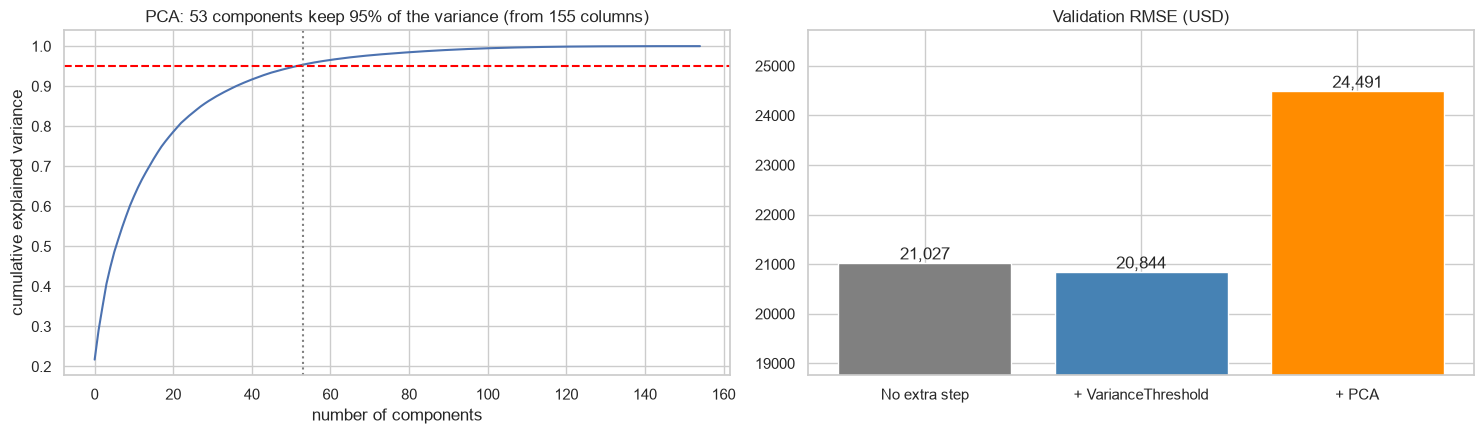

VarianceThreshold: USED (0.991x error)
PCA: not used (1.175x error, and it loses interpretability)


In [ ]:
base = quick_val_rmse(FEATURES)
with_var = quick_val_rmse(FEATURES, var_filter=True)
USE_VAR = with_var <= base * TOL
best_so_far = with_var if USE_VAR else base

with_pca = quick_val_rmse(FEATURES, var_filter=USE_VAR, pca=True)
USE_PCA = with_pca < best_so_far * 0.98

X_enc = Pipeline(prep_steps(FEATURES, var_filter=USE_VAR)).fit_transform(train_df[FEATURES])
pca_full = PCA(random_state=SEED).fit(X_enc)
n95 = np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.95) + 1

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(np.cumsum(pca_full.explained_variance_ratio_))
ax[0].axhline(0.95, color='red', ls='--')
ax[0].axvline(n95, color='grey', ls=':')
ax[0].set_title(f'PCA: {n95} components keep 95% of the variance (from {X_enc.shape[1]} columns)')
ax[0].set_xlabel('number of components')
ax[0].set_ylabel('cumulative explained variance')
bars = ax[1].bar(['No extra step', '+ VarianceThreshold', '+ PCA'], [base, with_var, with_pca],
                 color=['grey', 'steelblue', 'darkorange'])
ax[1].bar_label(bars, fmt='{:,.0f}')
ax[1].set_ylim(min(base, with_var, with_pca) * 0.9, max(base, with_var, with_pca) * 1.05)
ax[1].set_title('Validation RMSE (USD)')
save_show('reduction_variance_threshold_pca')

print(f'VarianceThreshold: {"USED" if USE_VAR else "not used"} ({with_var / base:.3f}x error)')
print(f'PCA: {"USED" if USE_PCA else "not used"} ({with_pca / best_so_far:.3f}x error, and it loses interpretability)')

## B9. VIF check & final feature count

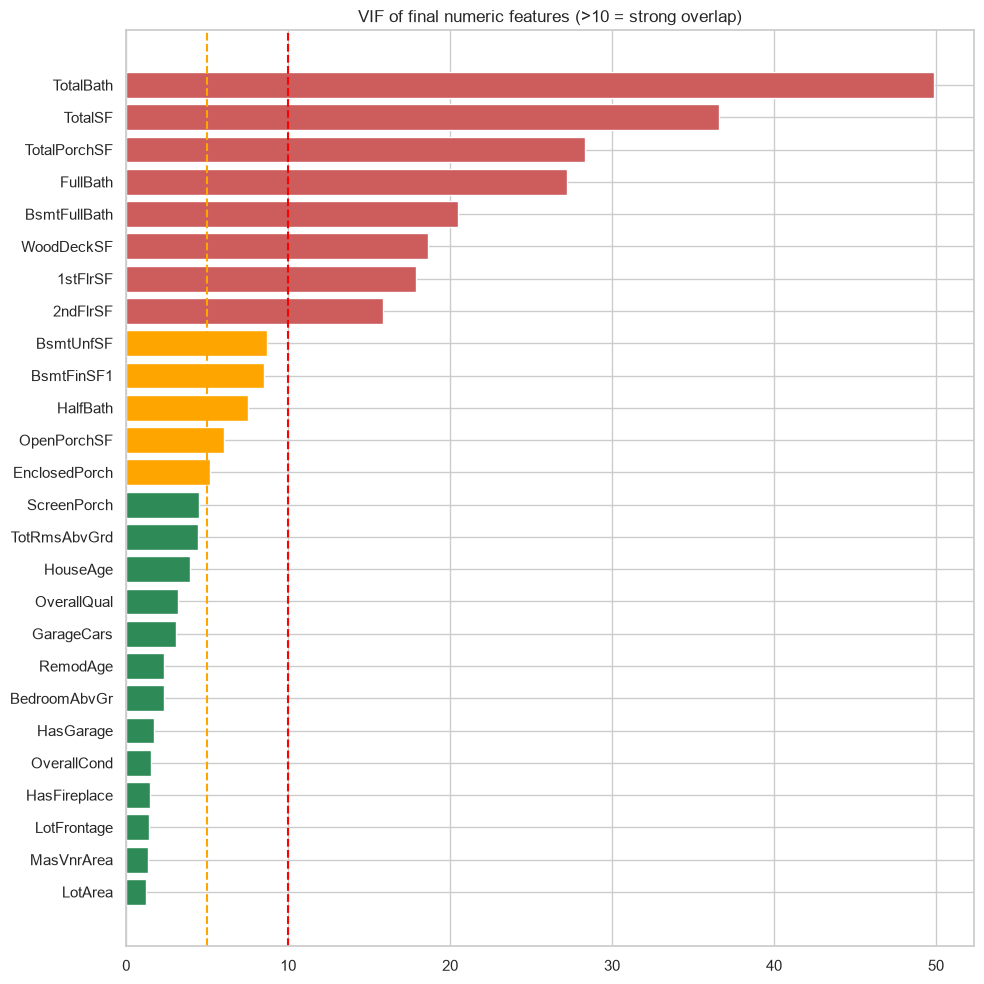

VIF > 10: ['2ndFlrSF', '1stFlrSF', 'WoodDeckSF', 'BsmtFullBath', 'FullBath', 'TotalPorchSF', 'TotalSF', 'TotalBath']
These are totals and their parts (e.g. TotalSF and 1stFlrSF). Ridge handles the overlap and trees are not affected,
so VIF is reported as a check only.


In [ ]:
def vif(df):
    X = (df - df.mean()) / df.std()
    out = {}
    for col in X.columns:
        r2 = LinearRegression().fit(X.drop(columns=col), X[col]).score(X.drop(columns=col), X[col])
        out[col] = 1 / (1 - r2) if r2 < 0.9999 else np.inf
    return pd.Series(out).sort_values()

vifs = vif(train_df[FEATURES].select_dtypes('number'))
plt.figure(figsize=(10, 10))
plt.barh(vifs.index, vifs, color=['indianred' if v > 10 else 'orange' if v > 5 else 'seagreen' for v in vifs])
plt.axvline(5, color='orange', ls='--')
plt.axvline(10, color='red', ls='--')
plt.title('VIF of final numeric features (>10 = strong overlap)')
save_show('reduction_vif')
print('VIF > 10:', list(vifs[vifs > 10].index))
print('These are totals and their parts (e.g. TotalSF and 1stFlrSF). Ridge handles the overlap and trees are not affected,')
print('so VIF is reported as a check only.')

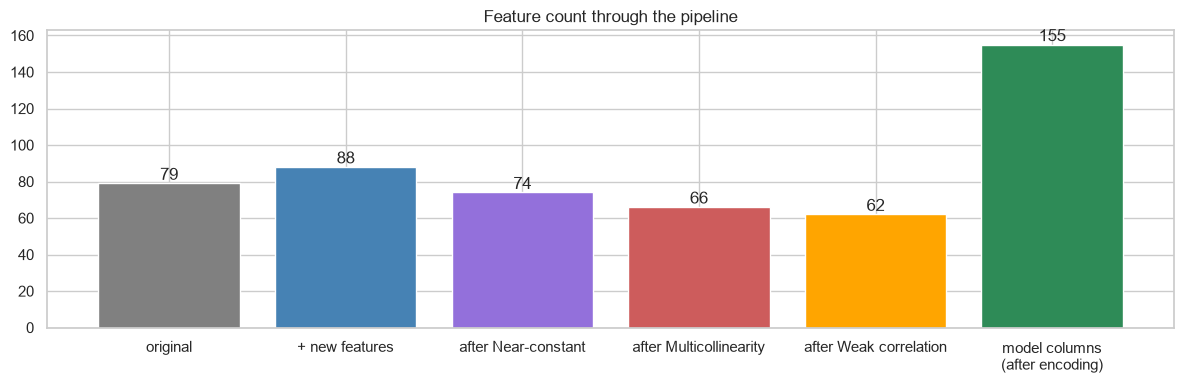

FINAL: 62 features (26 numeric + 36 categorical) -> 155 model columns after encoding
Dropped: ['Street', 'Utilities', 'LandSlope', 'Condition2', 'YearBuilt', 'YearRemodAdd', 'RoofMatl', 'BsmtFinSF2', 'TotalBsmtSF', 'Heating', 'LowQualFinSF', 'GrLivArea', 'BsmtHalfBath', 'KitchenAbvGr', 'Fireplaces', 'GarageYrBlt', 'GarageArea', '3SsnPorch', 'PoolArea', 'PoolQC', 'MiscFeature', 'MiscVal', 'MoSold', 'YrSold', 'HasBsmt', 'Has2ndFlr']


In [ ]:
X_train, X_val, X_test = train_df[FEATURES], val_df[FEATURES], test_df[FEATURES]
prep = Pipeline(prep_steps(FEATURES, USE_VAR, USE_PCA)).fit(X_train)
n_model_cols = prep.transform(X_train).shape[1]
n_numeric = len(X_train.select_dtypes('number').columns)

funnel = pd.Series({'original': len(all_features), '+ new features': len(all_cols)})
for _, row in steps_log.iloc[1:].iterrows():
    funnel['after ' + row['step']] = row['features']
funnel['model columns\n(after encoding)'] = n_model_cols
bars = plt.figure(figsize=(12, 4)).gca().bar(funnel.index, funnel, color=['grey', 'steelblue', 'mediumpurple', 'indianred', 'orange', 'seagreen'])
plt.bar_label(bars)
plt.title('Feature count through the pipeline')
save_show('reduction_feature_funnel')

print(f'FINAL: {len(FEATURES)} features ({n_numeric} numeric + {len(FEATURES) - n_numeric} categorical) '
      f'-> {n_model_cols} model columns after encoding')
dropped = [c for c in all_cols if c not in FEATURES]
print('Dropped:', dropped)

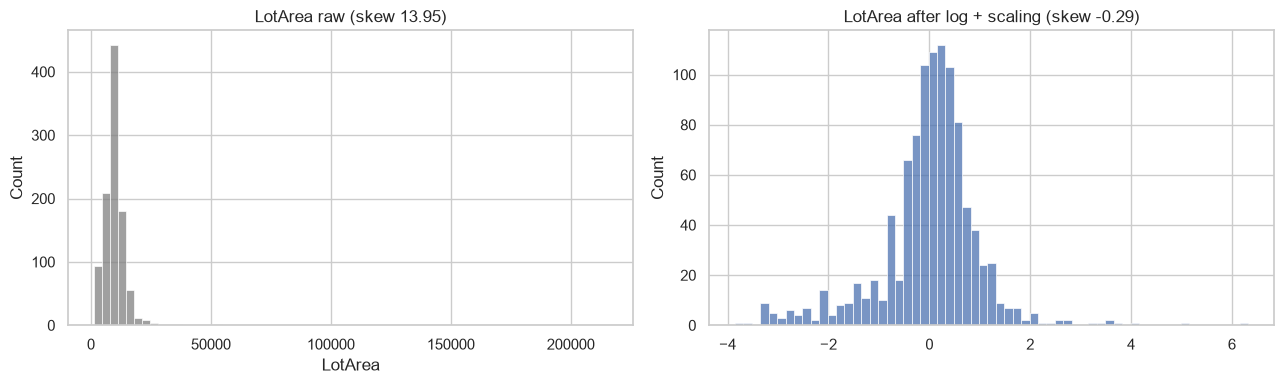

In [ ]:
# what preprocessing does to a skewed feature
col = 'LotArea' if 'LotArea' in FEATURES else X_train.select_dtypes('number').columns[0]
enc = Pipeline(prep_steps(FEATURES)).fit(X_train)
names = list(enc.get_feature_names_out())
after = enc.transform(X_train)[:, names.index([n for n in names if n.endswith('__' + col)][0])]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(X_train[col], ax=ax[0], color='grey').set_title(f'{col} raw (skew {X_train[col].skew():.2f})')
sns.histplot(after, ax=ax[1]).set_title(f'{col} after log + scaling (skew {pd.Series(after).skew():.2f})')
save_show('preprocessing_before_after')

---
# Part C — Model development & tuning
**Owner: IT24101843 — Dharmadasa K.A.Y.T.H.**

## C1. Baseline + three alternatives
| Role | Model | Why |
|---|---|---|
| Baseline | Linear Regression | simplest reference |
| Alternative 1 | Ridge | linear with L2 penalty; handles overlapping features |
| Alternative 2 | Random Forest | non-linear, bagging |
| Alternative 3 | Gradient Boosting | non-linear, boosting; usually strong on tables |

Each model is a full pipeline (preprocessing + model), trained on the training split and compared on validation.

In [ ]:
def make_model(model):
    return Pipeline(prep_steps(FEATURES, USE_VAR, USE_PCA) + [('model', model)])

results, models = [], {}

def evaluate(name, model):
    pipe = make_model(model).fit(X_train, y_train)
    models[name] = pipe
    p_train, p_val = pipe.predict(X_train), pipe.predict(X_val)
    results.append({'Model': name,
                    'Train RMSE': usd_rmse(y_train, p_train),
                    'Val RMSE': usd_rmse(y_val, p_val),
                    'Val MSE': usd_rmse(y_val, p_val) ** 2,
                    'Val MAE': mean_absolute_error(np.expm1(y_val), np.expm1(p_val)),
                    'Train R2': r2_score(y_train, p_train),
                    'Val R2': r2_score(y_val, p_val)})

evaluate('Linear Regression (baseline)', LinearRegression())
evaluate('Ridge', Ridge(alpha=10))
evaluate('Random Forest', RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))
evaluate('Gradient Boosting', GradientBoostingRegressor(random_state=SEED))
pd.DataFrame(results).round(4)

,Model,Train RMSE,Val RMSE,Val MSE,Val MAE,Train R2,Val R2
0,Linear Regression (baseline),19500.9473,21225.4980,4.505218e+08,14935.3512,0.9458,0.9145
1,Ridge,20123.5704,20726.5012,4.295879e+08,14245.5126,0.9413,0.9123
2,Random Forest,10862.1618,24891.1395,6.195688e+08,17617.4519,0.9852,0.8618
3,Gradient Boosting,13111.5100,20961.4329,4.393817e+08,14520.4045,0.9685,0.8962


## C2. Hyperparameter tuning (GridSearchCV, 5-fold CV on the training split)
GridSearchCV tries every combination in a small grid. Each combination is scored with 5-fold cross-validation on the training split only, and the whole pipeline is re-fitted inside each fold. Validation and test data are never used for tuning.

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
grids = {
    'Ridge': (Ridge(), {'model__alpha': [0.3, 1, 3, 5, 10, 15, 20, 30, 50, 100]}),
    'Random Forest': (RandomForestRegressor(random_state=SEED, n_jobs=1),
                      {'model__n_estimators': [300, 600], 'model__max_depth': [None, 20],
                       'model__min_samples_leaf': [1, 2], 'model__max_features': ['sqrt', 0.3]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=SEED, subsample=0.8, min_samples_leaf=5),
                          {'model__n_estimators': [300, 600, 900], 'model__learning_rate': [0.03, 0.05],
                           'model__max_depth': [3, 4], 'model__max_features': ['sqrt', 0.5]}),
}

searches = {}
for name, (model, grid) in grids.items():
    search = GridSearchCV(make_model(model), grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f'{name}: best CV RMSE (log) = {-search.best_score_:.4f} with {search.best_params_}')

Ridge: best CV RMSE (log) = 0.1096 with {'model__alpha': 15}


Random Forest: best CV RMSE (log) = 0.1244 with {'model__max_depth': 20, 'model__max_features': 0.3, 'model__min_samples_leaf': 1, 'model__n_estimators': 600}


Gradient Boosting: best CV RMSE (log) = 0.1113 with {'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__max_features': 0.5, 'model__n_estimators': 600}


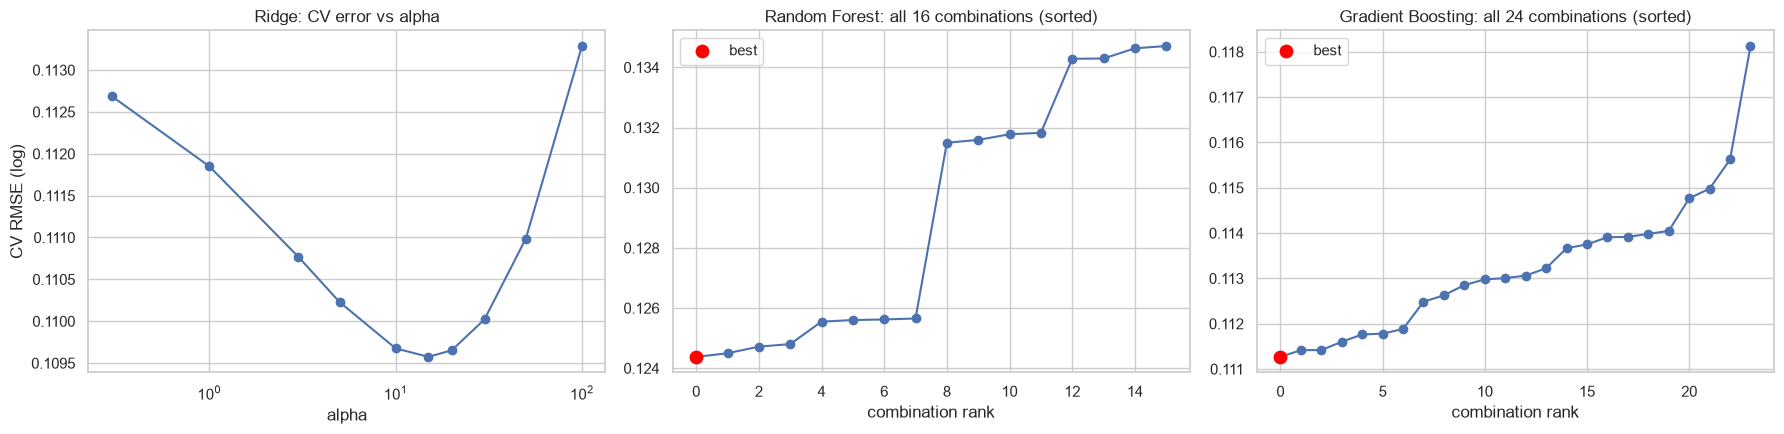

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ridge_cv = pd.DataFrame(searches['Ridge'].cv_results_)
ax[0].plot(ridge_cv['param_model__alpha'].astype(float), -ridge_cv['mean_test_score'], 'o-')
ax[0].set_xscale('log')
ax[0].set_title('Ridge: CV error vs alpha')
ax[0].set_xlabel('alpha')
ax[0].set_ylabel('CV RMSE (log)')
for a, name in zip(ax[1:], ['Random Forest', 'Gradient Boosting']):
    scores = np.sort(-searches[name].cv_results_['mean_test_score'])
    a.plot(scores, 'o-')
    a.scatter(0, scores[0], color='red', s=80, zorder=5, label='best')
    a.set_title(f'{name}: all {len(scores)} combinations (sorted)')
    a.set_xlabel('combination rank')
    a.legend()
save_show('tuning_results')

for name in grids:
    best = searches[name].best_estimator_.named_steps['model']
    evaluate(f'{name} (tuned)', clone(best))

## C3. Model comparison log (validation split)

,Model,Train RMSE,Val RMSE,Val MSE,Val MAE,Train R2,Val R2
0,Gradient Boosting (tuned),7903.0,19491.0,379917199.0,13672.0,0.9884,0.9095
1,Ridge,20124.0,20727.0,429587850.0,14246.0,0.9413,0.9123
2,Ridge (tuned),20294.0,20853.0,434851390.0,14284.0,0.9401,0.9122
3,Gradient Boosting,13112.0,20961.0,439381670.0,14520.0,0.9685,0.8962
4,Linear Regression (baseline),19501.0,21225.0,450521767.0,14935.0,0.9458,0.9145
5,Random Forest (tuned),10522.0,22350.0,499501067.0,15382.0,0.9867,0.8783
6,Random Forest,10862.0,24891.0,619568825.0,17617.0,0.9852,0.8618


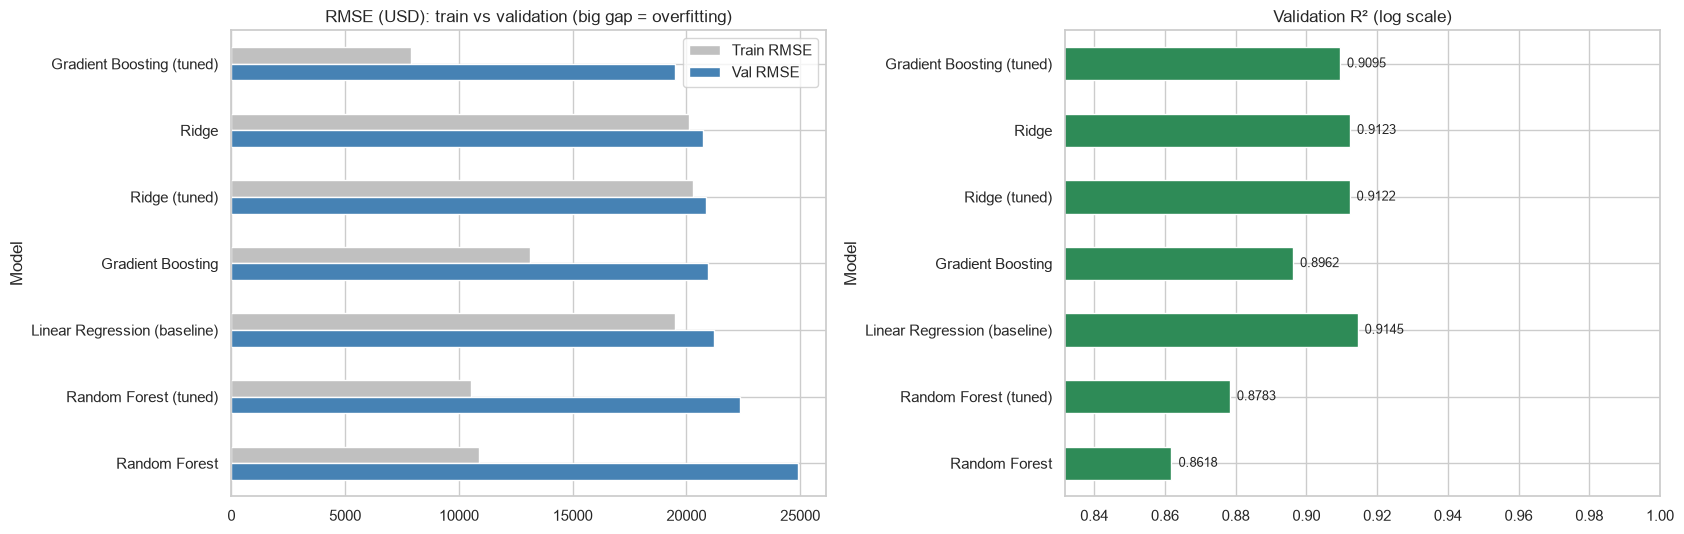

In [ ]:
comparison = pd.DataFrame(results).sort_values('Val RMSE').reset_index(drop=True)
display(comparison.round({'Train RMSE': 0, 'Val RMSE': 0, 'Val MSE': 0, 'Val MAE': 0, 'Train R2': 4, 'Val R2': 4}))

fig, ax = plt.subplots(1, 2, figsize=(17, 5.5))
comparison.set_index('Model')[['Train RMSE', 'Val RMSE']].plot(kind='barh', ax=ax[0], color=['silver', 'steelblue'])
ax[0].invert_yaxis()
ax[0].set_title('RMSE (USD): train vs validation (big gap = overfitting)')
comparison.set_index('Model')['Val R2'].plot(kind='barh', ax=ax[1], color='seagreen', xlim=(comparison['Val R2'].min() - 0.03, 1))
ax[1].invert_yaxis()
ax[1].set_title('Validation R² (log scale)')
for i, v in enumerate(comparison['Val R2']):
    ax[1].text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)
save_show('model_comparison_validation')

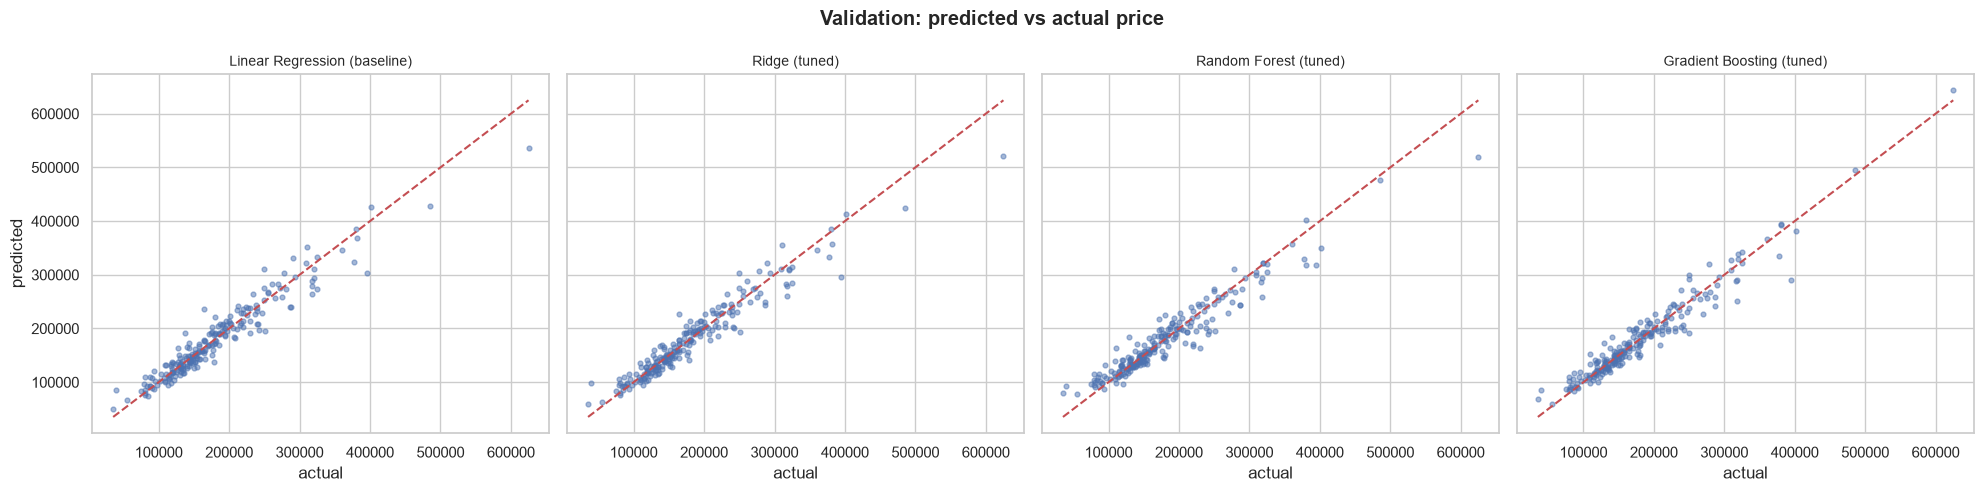

In [ ]:
show = ['Linear Regression (baseline)', 'Ridge (tuned)', 'Random Forest (tuned)', 'Gradient Boosting (tuned)']
fig, ax = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)
line = [np.expm1(y_val).min(), np.expm1(y_val).max()]
for a, name in zip(ax, show):
    a.scatter(np.expm1(y_val), np.expm1(models[name].predict(X_val)), s=12, alpha=0.5)
    a.plot(line, line, 'r--')
    a.set_title(name, fontsize=10)
    a.set_xlabel('actual')
ax[0].set_ylabel('predicted')
fig.suptitle('Validation: predicted vs actual price', fontweight='bold')
save_show('validation_pred_vs_actual')

,CV R2 mean,CV R2 std
Ridge (tuned),0.9224,0.0079
Gradient Boosting (tuned),0.9197,0.0122
Linear Regression (baseline),0.9163,0.0076
Random Forest (tuned),0.8997,0.0150


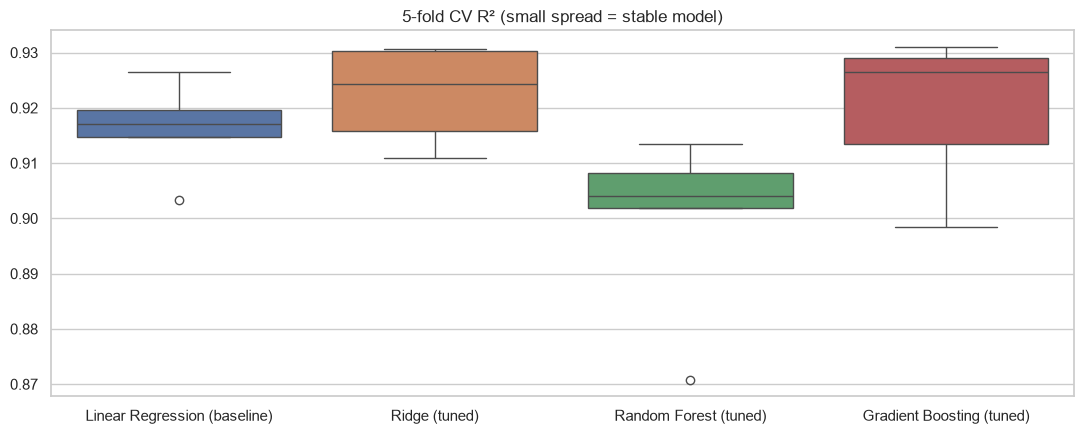

In [ ]:
# stability check: 5-fold CV R² on the training split
cv_r2 = {name: cross_val_score(clone(models[name]), X_train, y_train, cv=cv, scoring='r2', n_jobs=-1) for name in show}
cv_table = pd.DataFrame({'CV R2 mean': {n: s.mean() for n, s in cv_r2.items()},
                         'CV R2 std': {n: s.std() for n, s in cv_r2.items()}}).round(4)
display(cv_table.sort_values('CV R2 mean', ascending=False))

plt.figure(figsize=(11, 4.5))
sns.boxplot(data=pd.DataFrame(cv_r2))
plt.title('5-fold CV R² (small spread = stable model)')
save_show('cv_robustness_boxplot')

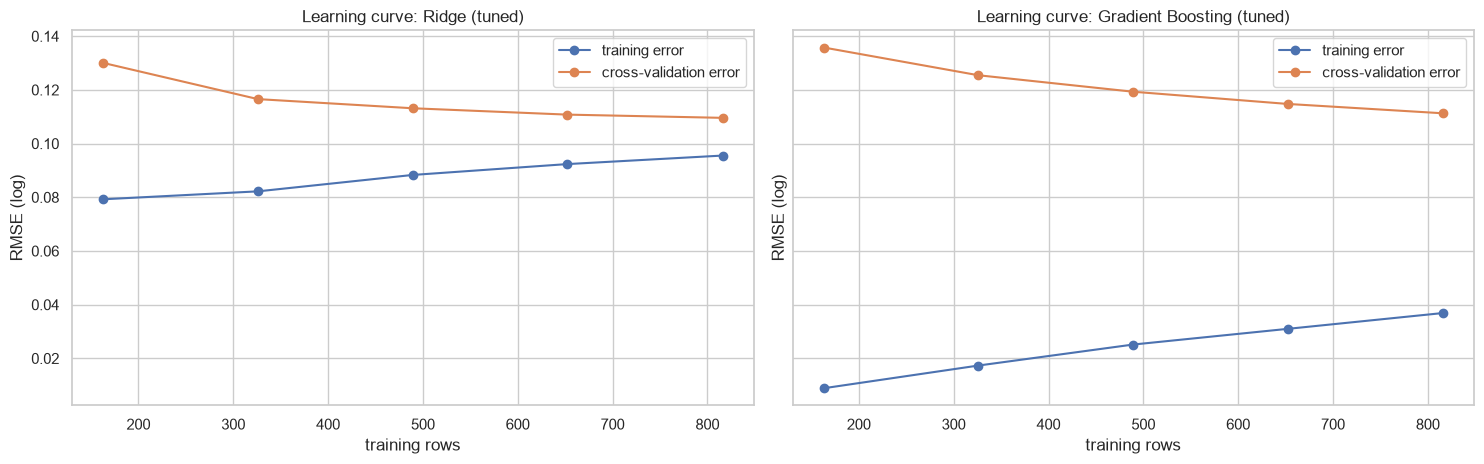

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for a, name in zip(ax, ['Ridge (tuned)', 'Gradient Boosting (tuned)']):
    sizes, tr, va = learning_curve(clone(models[name]), X_train, y_train, cv=cv, n_jobs=-1,
                                   train_sizes=np.linspace(0.2, 1, 5), scoring='neg_root_mean_squared_error')
    a.plot(sizes, -tr.mean(1), 'o-', label='training error')
    a.plot(sizes, -va.mean(1), 'o-', label='cross-validation error')
    a.set_title(f'Learning curve: {name}')
    a.set_xlabel('training rows')
    a.set_ylabel('RMSE (log)')
    a.legend()
save_show('learning_curves')

## C4. Final model choice (validation only)
**Rule:** average the best **linear** model and the best **tree** model (50/50). The two families make different kinds of mistakes, so they balance each other out. Taking the "top 2 overall" could pick two Ridge models that make the same mistakes.

In [ ]:
linear = ['Linear Regression (baseline)', 'Ridge', 'Ridge (tuned)']
best_linear = comparison[comparison['Model'].isin(linear)].iloc[0]['Model']
best_tree = comparison[~comparison['Model'].isin(linear)].iloc[0]['Model']
model_a, model_b = models[best_linear], models[best_tree]

def ensemble_predict(X):
    return 0.5 * model_a.predict(X) + 0.5 * model_b.predict(X)

def all_metrics(y_log, pred_log):
    rmse = usd_rmse(y_log, pred_log)
    return {'R2': r2_score(y_log, pred_log), 'RMSE': rmse, 'MSE': rmse ** 2,
            'MAE': mean_absolute_error(np.expm1(y_log), np.expm1(pred_log))}

print(f'Chosen: {best_linear} + {best_tree}')
pd.DataFrame({best_linear: all_metrics(y_val, model_a.predict(X_val)),
              best_tree: all_metrics(y_val, model_b.predict(X_val)),
              'Ensemble 50/50': all_metrics(y_val, ensemble_predict(X_val))}).T.round(4)

Chosen: Ridge + Gradient Boosting (tuned)


,R2,RMSE,MSE,MAE
Ridge,0.9123,20726.5012,4.295879e+08,14245.5126
Gradient Boosting (tuned),0.9095,19491.4648,3.799172e+08,13672.0198
Ensemble 50/50,0.9176,18615.0939,3.465217e+08,12903.8782


---
# Part D — Evaluation, diagnostics & feature importance
**Owner: IT24101829 — Ranasinghe R.P.V.K.**

## D1. Final test evaluation (the test split is used ONCE, here)

In [ ]:
test_pred = ensemble_predict(X_test)
final = all_metrics(y_test, test_pred)

print('=' * 50)
print('FINAL TEST RESULT (headline)')
print('=' * 50)
print(f"Model : {best_linear} + {best_tree}")
print(f"RMSE  : {final['RMSE']:,.0f} USD")
print(f"MSE   : {final['MSE']:,.0f} USD²")
print(f"MAE   : {final['MAE']:,.0f} USD")
print(f"R²    : {final['R2']:.4f} (log scale)")

FINAL TEST RESULT (headline)
Model : Ridge + Gradient Boosting (tuned)
RMSE  : 21,673 USD
MSE   : 469,699,057 USD²
MAE   : 13,981 USD
R²    : 0.9049 (log scale)


## D2. Metrics log: train vs validation vs test

,Split,Model,R2,RMSE,MSE,MAE
0,Train,Ensemble,0.9725,13259.2204,1.758069e+08,8606.5903
3,Validation,Ensemble,0.9176,18615.0939,3.465217e+08,12903.8782
6,Test,Ensemble,0.9049,21672.5415,4.696991e+08,13980.6081


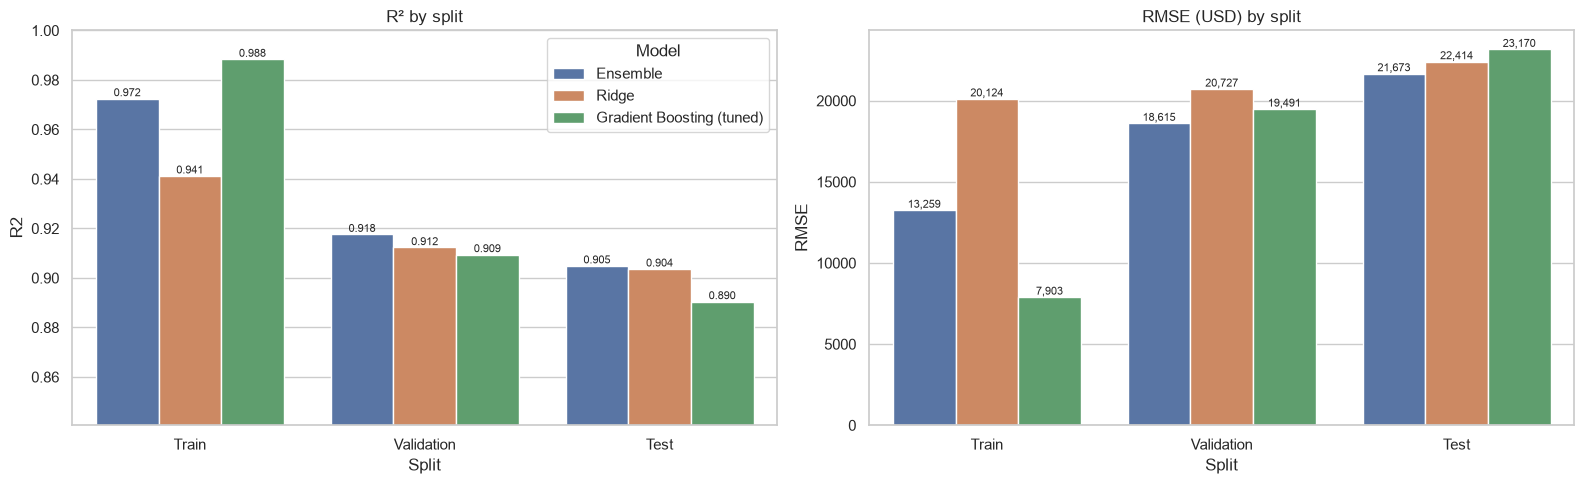

In [ ]:
rows = []
for split, X, y in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]:
    for name, pred in [('Ensemble', ensemble_predict(X)), (best_linear, model_a.predict(X)), (best_tree, model_b.predict(X))]:
        rows.append({'Split': split, 'Model': name, **all_metrics(y, pred)})
metrics_log = pd.DataFrame(rows)
metrics_log.to_csv('metrics_log.csv', index=False)
display(metrics_log[metrics_log['Model'] == 'Ensemble'].round(4))

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=metrics_log, x='Split', y='R2', hue='Model', ax=ax[0])
ax[0].set_ylim(metrics_log['R2'].min() - 0.05, 1)
ax[0].set_title('R² by split')
sns.barplot(data=metrics_log, x='Split', y='RMSE', hue='Model', ax=ax[1])
ax[1].set_title('RMSE (USD) by split')
ax[1].legend().remove()
for a in ax:
    for bars in a.containers:
        a.bar_label(bars, fmt='%.3f' if a is ax[0] else '{:,.0f}', fontsize=8)
save_show('final_train_val_test_scores')

> **Why no ROC/AUC?** ROC/AUC measures how well a classifier separates classes. We predict a continuous price, so RMSE, MSE, MAE, R², residuals and error by price band are the right tools.

## D3. Residual analysis

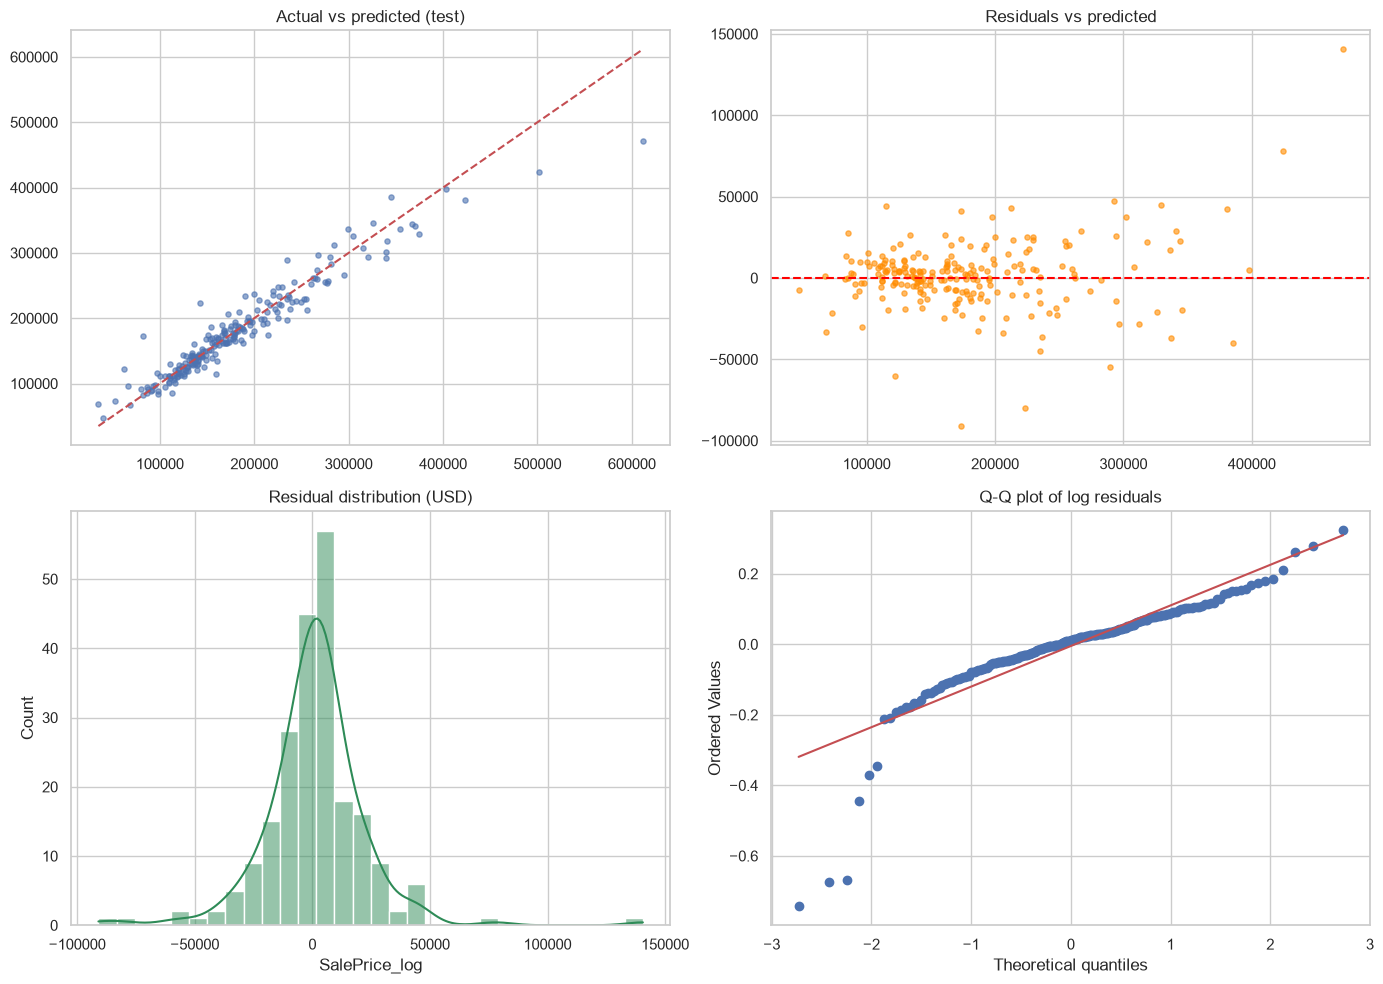

In [ ]:
actual, pred = np.expm1(y_test), np.expm1(test_pred)
resid = actual - pred

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0, 0].scatter(actual, pred, s=14, alpha=0.6)
ax[0, 0].plot([actual.min(), actual.max()], [actual.min(), actual.max()], 'r--')
ax[0, 0].set_title('Actual vs predicted (test)')
ax[0, 1].scatter(pred, resid, s=14, alpha=0.6, color='darkorange')
ax[0, 1].axhline(0, color='red', ls='--')
ax[0, 1].set_title('Residuals vs predicted')
sns.histplot(resid, kde=True, ax=ax[1, 0], color='seagreen').set_title('Residual distribution (USD)')
stats.probplot(y_test - test_pred, plot=ax[1, 1])
ax[1, 1].set_title('Q-Q plot of log residuals')
save_show('test_residual_analysis')

## D4. Error diagnostics by price band

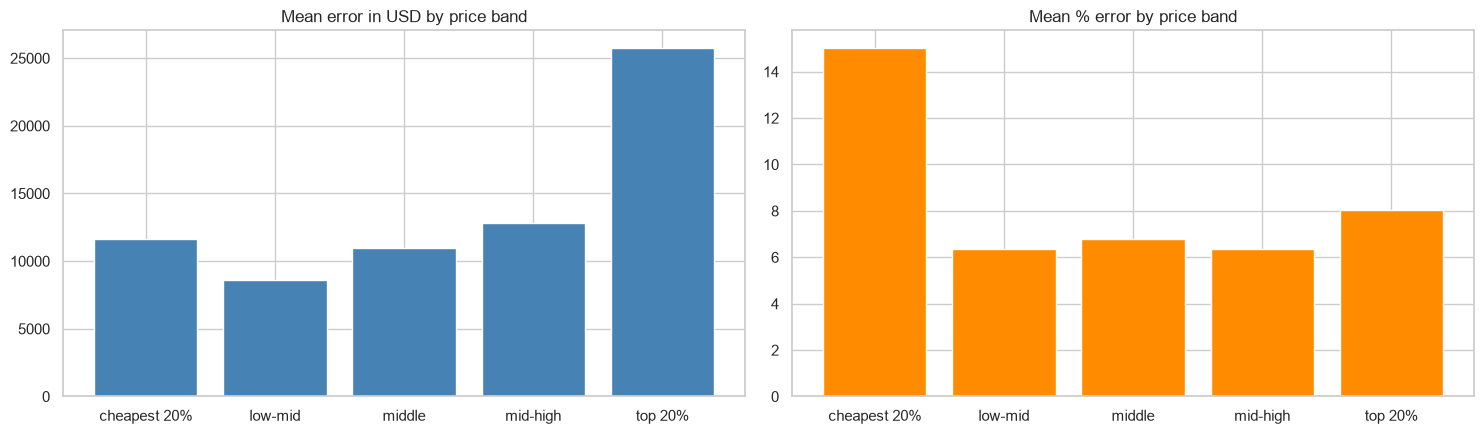

,MAE,MAPE,houses
band,,,
cheapest 20%,11621.0,15.0,44
low-mid,8641.2,6.4,44
middle,10988.1,6.8,43
mid-high,12826.7,6.3,44
top 20%,25758.0,8.0,44


In [ ]:
band = pd.qcut(actual, 5, labels=['cheapest 20%', 'low-mid', 'middle', 'mid-high', 'top 20%'])
by_band = pd.DataFrame({'band': band, 'abs_err': resid.abs(), 'pct_err': resid.abs() / actual * 100}) \
            .groupby('band', observed=True).agg(MAE=('abs_err', 'mean'), MAPE=('pct_err', 'mean'), houses=('abs_err', 'size'))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(by_band.index.astype(str), by_band['MAE'], color='steelblue')
ax[0].set_title('Mean error in USD by price band')
ax[1].bar(by_band.index.astype(str), by_band['MAPE'], color='darkorange')
ax[1].set_title('Mean % error by price band')
save_show('test_error_by_price_band')
by_band.round(1)

## D5. Feature importance (secondary lens: what drives price?)

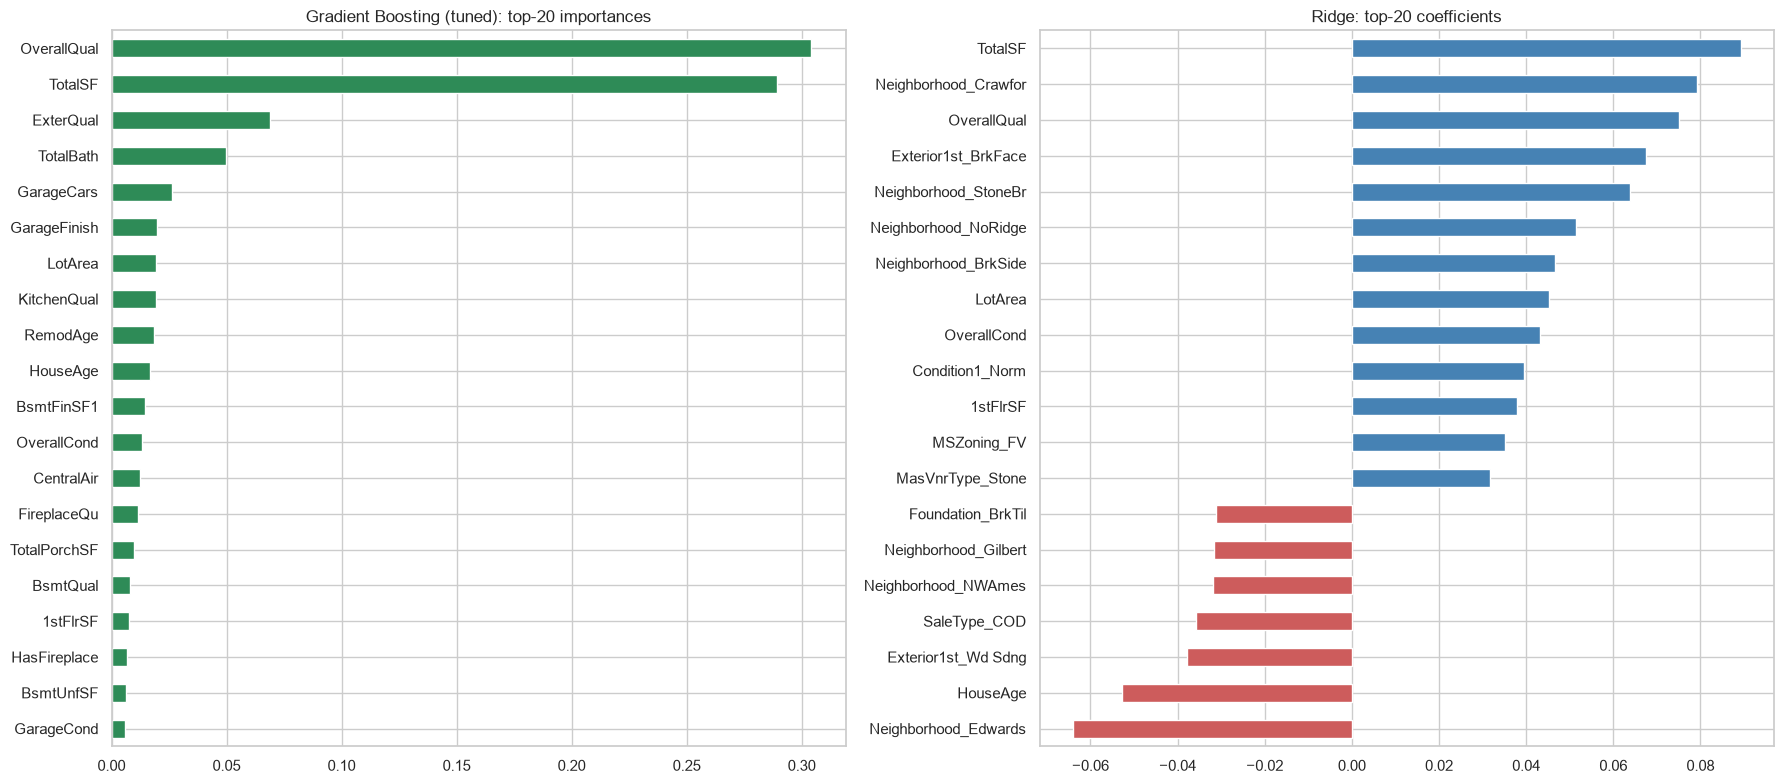

Top price drivers: OverallQual, TotalSF, ExterQual, TotalBath, GarageCars, GarageFinish, LotArea, KitchenQual


In [ ]:
names = [n.split('__')[-1] for n in model_b[:-1].get_feature_names_out()]
tree_imp = pd.Series(model_b.named_steps['model'].feature_importances_, index=names).nlargest(20)
coefs = pd.Series(model_a.named_steps['model'].coef_, index=names)
top_coefs = coefs[coefs.abs().nlargest(20).index]

fig, ax = plt.subplots(1, 2, figsize=(18, 8))
tree_imp.sort_values().plot(kind='barh', ax=ax[0], color='seagreen', title=f'{best_tree}: top-20 importances')
top_coefs.sort_values().plot(kind='barh', ax=ax[1], title=f'{best_linear}: top-20 coefficients',
                             color=['indianred' if v < 0 else 'steelblue' for v in top_coefs.sort_values()])
save_show('feature_importance')
print('Top price drivers:', ', '.join(tree_imp.index[:8]))

## D6. Refit on all labelled data & Kaggle submission
The model choice and settings are now **frozen**. We re-learn the fill values and the pipeline on all 1,460 labelled sales and refit the same two models. The test score above stays our honest performance estimate.

submission.csv saved (1459 rows), models trained on 1458 rows


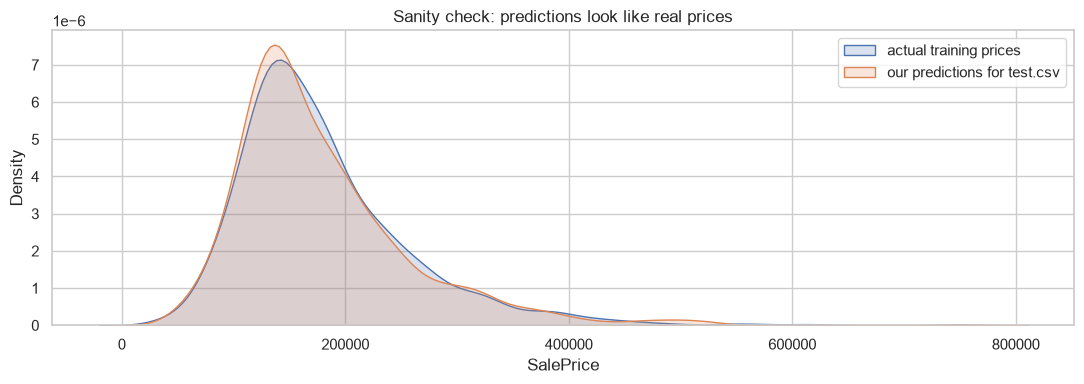

,Id,SalePrice
0,1461,119860.502329
1,1462,168782.306138
2,1463,184405.558909
3,1464,197355.198804
4,1465,195779.371654


In [ ]:
full = basic_clean(train_raw).drop_duplicates(subset=train_raw.columns.drop('Id'))
lot_by_area = full.groupby('Neighborhood')['LotFrontage'].median()   # re-learned from all labelled rows
lot_median = full['LotFrontage'].median()
electrical_mode = full['Electrical'].mode()[0]
full = add_features(fill_missing(full))
full = full[~((full['GrLivArea'] > 4000) & (full['SalePrice'] < 300000))]
y_full = np.log1p(full['SalePrice'])

kaggle_test = add_features(fill_missing(basic_clean(test_raw)))
final_a = clone(model_a).fit(full[FEATURES], y_full)
final_b = clone(model_b).fit(full[FEATURES], y_full)
sub_pred = 0.5 * np.expm1(final_a.predict(kaggle_test[FEATURES])) + 0.5 * np.expm1(final_b.predict(kaggle_test[FEATURES]))

submission = pd.DataFrame({'Id': test_raw['Id'], 'SalePrice': sub_pred})
submission.to_csv('submission.csv', index=False)
print(f'submission.csv saved ({len(submission)} rows), models trained on {len(full)} rows')

plt.figure(figsize=(11, 4))
sns.kdeplot(train_raw['SalePrice'], fill=True, alpha=0.2, label='actual training prices')
sns.kdeplot(submission['SalePrice'], fill=True, alpha=0.2, label='our predictions for test.csv')
plt.legend()
plt.title('Sanity check: predictions look like real prices')
save_show('submission_distribution')
submission.head()

---
# Wrap-up *(all members)*

## Workflow diagram
```mermaid
flowchart TD
    A[Business problem + lens] --> B[Load data, fingerprint, data dictionary]
    B --> C[Missing values, duplicates, EDA, insight log]
    C --> D[Row-level cleaning]
    D --> E[Stratified 70/15/15 split]
    E --> F[Fill real gaps with train-only stats]
    F --> G[Outliers removed from train only]
    G --> H[Feature engineering]
    H --> I[Reduction: near-constant, r>0.8, weak r - each checked on validation]
    I --> J[VarianceThreshold / PCA test, VIF check]
    J --> K[Encoding + scaling pipeline]
    K --> L[Baseline LR + Ridge, RF, GB]
    L --> M[GridSearchCV tuning, 5-fold CV on train]
    M --> N[Validation comparison, CV stability, learning curves]
    N --> O[Ensemble: best linear + best tree]
    O --> P[Test split scored once]
    P --> Q[Residuals, error by band, feature importance]
    Q --> R[Refit on all data, submission]
    R --> S[Recommendation + limitations]
```

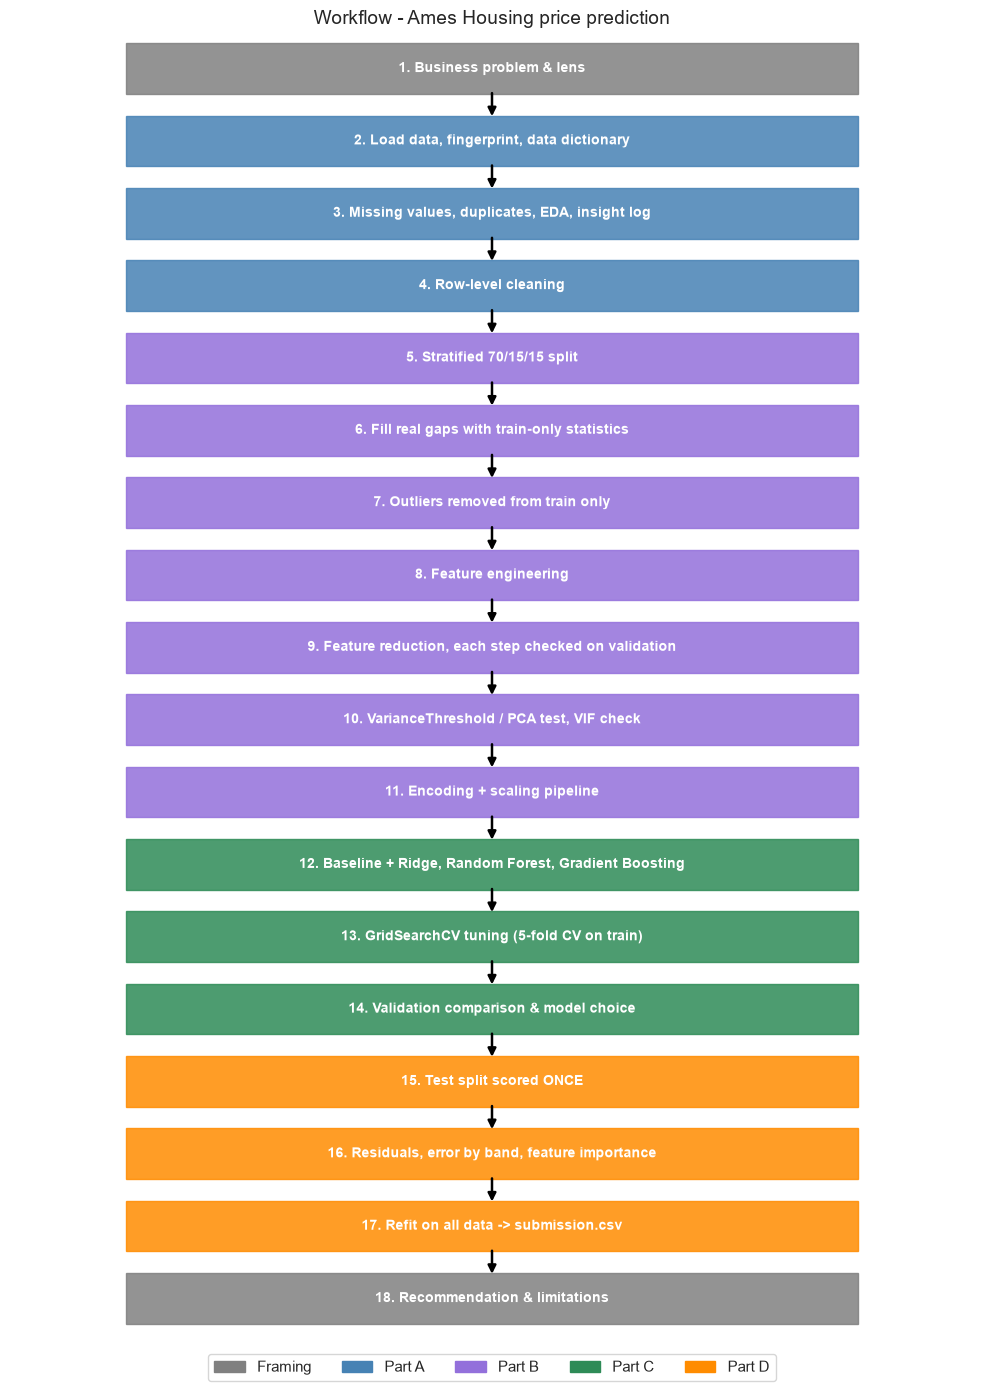

In [ ]:
steps = [('Business problem & lens', 'Framing'), ('Load data, fingerprint, data dictionary', 'Part A'),
         ('Missing values, duplicates, EDA, insight log', 'Part A'), ('Row-level cleaning', 'Part A'),
         ('Stratified 70/15/15 split', 'Part B'), ('Fill real gaps with train-only statistics', 'Part B'),
         ('Outliers removed from train only', 'Part B'), ('Feature engineering', 'Part B'),
         ('Feature reduction, each step checked on validation', 'Part B'), ('VarianceThreshold / PCA test, VIF check', 'Part B'),
         ('Encoding + scaling pipeline', 'Part B'), ('Baseline + Ridge, Random Forest, Gradient Boosting', 'Part C'),
         ('GridSearchCV tuning (5-fold CV on train)', 'Part C'), ('Validation comparison & model choice', 'Part C'),
         ('Test split scored ONCE', 'Part D'), ('Residuals, error by band, feature importance', 'Part D'),
         ('Refit on all data -> submission.csv', 'Part D'), ('Recommendation & limitations', 'Framing')]
colours = {'Framing': 'grey', 'Part A': 'steelblue', 'Part B': 'mediumpurple', 'Part C': 'seagreen', 'Part D': 'darkorange'}

fig, ax = plt.subplots(figsize=(10, 14))
ax.set_xlim(0, 10)
ax.set_ylim(0.3, len(steps) + 0.5)
ax.axis('off')
for i, (text, part) in enumerate(steps):
    y = len(steps) - i
    ax.add_patch(plt.Rectangle((1.2, y - 0.35), 7.6, 0.7, color=colours[part], alpha=0.85))
    ax.text(5, y, f'{i + 1}. {text}', ha='center', va='center', color='white', fontweight='bold', fontsize=10)
    if i < len(steps) - 1:
        ax.annotate('', xy=(5, y - 0.66), xytext=(5, y - 0.34),
                    arrowprops=dict(arrowstyle='-|>', lw=1.8, color='black', shrinkA=0, shrinkB=0))
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()], colours.keys(),
          loc='lower center', ncol=5, bbox_to_anchor=(0.5, -0.03))
ax.set_title('Workflow - Ames Housing price prediction', fontsize=14)
save_show('workflow_diagram')

## Decision log
| # | Decision | Alternatives | Why | Evidence |
|---|---|---|---|---|
| 1 | Regression on SalePrice | price bands (classification) | agency needs a dollar figure | canvas |
| 2 | Secondary lens: price drivers | segmentation | explains valuations with the same models | D5 |
| 3 | Predict log(price) | raw price | removes skew | A4 |
| 4 | Stratified 70/15/15 split on price deciles | random split, 80/20 | same price mix everywhere; separate val and test | B1 |
| 5 | Row-level cleaning before split, learned fills after | clean everything first | no leakage | A8, B2 |
| 6 | Absent features → 'None'/0 | drop columns, mean fill | NA means "doesn't have it" | A3 |
| 7 | LotFrontage = neighbourhood median (train) | global median | lot size depends on area | B2 |
| 8 | Remove 2 outliers from train only | keep; remove everywhere | val/test must stay realistic | B3 |
| 9 | New features (TotalSF, TotalBath, ages, flags) | raw only | stronger combined signals | B4 |
| 10 | Drop near-constant (≥95%) if validation agrees | keep all | no information | B5, B7 |
| 11 | \|r\| > 0.8 → drop weaker feature, if validation agrees | keep all | removes duplicate information | B5, B7 |
| 12 | Weak \|r\| < 0.10 dropped one by one, only with evidence | drop all blindly | correlation misses non-linear effects (e.g. OverallCond) | B7 |
| 13 | VarianceThreshold on encoded columns, if validation agrees | none | removes rare dummy columns | B8 |
| 14 | PCA only if clearly better (>2%) | always PCA | PCA hides feature meaning (breaks secondary lens) | B8 |
| 15 | VIF as a check only | drop until VIF < 10 | Ridge handles overlap; trees unaffected | B9 |
| 16 | Ordinal for quality, one-hot for other categories | target encoding | keeps order; target encoding risks leakage | B6 |
| 17 | Baseline + Ridge, RF, GB | trees only | rubric: baseline + ≥3 alternatives | C1 |
| 18 | GridSearchCV, 5-fold CV on train, pipeline re-fitted per fold | Optuna, tuning on validation | small grids, standard, reproducible, no leakage | C2 |
| 19 | Ensemble: best linear + best tree | single model, top-2 overall | different error patterns | C4 |
| 20 | Test split scored once | report validation score | validation was used for choices | D1 |
| 21 | Refit on all labelled data for submission | train-only models | uses every sale | D6 |

## Results & recommendation

In [ ]:
mape = by_band['MAPE'].mean()
print(f"Features used      : {len(FEATURES)} (from {len(all_features)} original + {len(new_features)} new)")
print(f"Final model        : {best_linear} + {best_tree} (50/50)")
print(f"Test performance   : RMSE {final['RMSE']:,.0f} USD | MAE {final['MAE']:,.0f} USD | R² {final['R2']:.4f}")
print(f"Typical error      : about {mape:.0f}% of the price")
print(f"Hardest homes      : {by_band['MAE'].idxmax()} (MAE {by_band['MAE'].max():,.0f} USD)")
print(f"Top price drivers  : {', '.join(tree_imp.index[:5])}")
print()
print('Recommendation for the agency:')
print(f"1. Use the model for a quick first valuation; expect about +/- {final['MAE']:,.0f} USD on a typical home.")
print('2. Quote a price range, not one number.')
print(f"3. Send '{by_band['MAE'].idxmax()}' and unusual homes to a human appraiser - errors are largest there.")
print('4. Explain prices with the top drivers (quality, size, age, location).')
print('5. Retrain on recent sales; do not use it for other cities or years without retraining.')

Features used      : 62 (from 79 original + 9 new)
Final model        : Ridge + Gradient Boosting (tuned) (50/50)
Test performance   : RMSE 21,673 USD | MAE 13,981 USD | R² 0.9049
Typical error      : about 9% of the price
Hardest homes      : top 20% (MAE 25,758 USD)
Top price drivers  : OverallQual, TotalSF, ExterQual, TotalBath, GarageCars

Recommendation for the agency:
1. Use the model for a quick first valuation; expect about +/- 13,981 USD on a typical home.
2. Quote a price range, not one number.
3. Send 'top 20%' and unusual homes to a human appraiser - errors are largest there.
4. Explain prices with the top drivers (quality, size, age, location).
5. Retrain on recent sales; do not use it for other cities or years without retraining.


## Limitations & responsible AI
1. **Scope:** one city (Ames, Iowa), 2006–2010, including the 2008 crash. Needs retraining for other markets or years.
2. **Small data:** 1,460 sales and few expensive homes, so errors are biggest in the top price band. The validation and test sets (219 rows each) are small, so scores are a bit noisy.
3. **Log target:** converting predictions back from log slightly under-predicts the average price.
4. **Feature filters are linear:** correlation rules can miss non-linear effects. The validation checks reduce this risk but can't remove it.
5. **Test-set honesty:** in an earlier version of this project, the ensemble rule was changed after test results had been seen. The final rule is justified on validation evidence alone, but the test score may be slightly optimistic.
6. **Missing factors:** interest rates, school quality and market trends are not in the data.

**Responsible AI:** `Neighborhood` can act as a proxy for income or demographics, so the model could repeat past pricing unfairness. Check errors by area, keep a human appraiser in the loop, show clients the price drivers, and monitor errors over time.

## Reproducibility & AI-use declaration
- Fixed seed (42), SHA-256 fingerprints and library versions are printed at the top. All fill values, filters, encoders, scalers and tuning are learned from training data only.
- Charts go to `figures/`, predictions to `submission.csv`, and metrics to `metrics_log.csv`.

Our group used AI tools only as a study aid and verified results against the notebook outputs, so the work and responsibility remain the team’s.

## Summary
We framed pricing as a **regression** problem, explored and cleaned the data (Part A), and built a **leak-free** preprocessing and feature pipeline in which every reduction step is backed by validation evidence (Part B). We compared a baseline with three alternatives tuned by cross-validation (Part C) and evaluated the final **linear + tree ensemble** once on an untouched test split. We then explained where the model does well and badly and which features drive price (Part D). The agency gets a fast, explainable, honestly evaluated first-valuation tool, with clear limits on when a human should step in.